# Лекция 12. Диффузионные модели

Курс «Современное компьютерное зрение». Блокнот рассчитан на Google Colab: все ячейки выполняются сверху вниз без дополнительной настройки, внешние зависимости — только torch, torchvision, scipy и matplotlib, которые в Colab уже установлены. Данные (MNIST) скачиваются автоматически.

Сохранённые выводы получены на CPU в режиме `FAST_DEV_RUN` (облегчённые сети и сокращённое обучение). Ветка с GPU в Colab написана, но не проверялась: на ней числа будут другими, переносить стоит направления эффектов.

Лекция продолжает лекцию 11: там генерация шла авторегрессией по дискретным токенам, здесь — постепенным удалением шума из непрерывного представления. В латентной диффузии (Stable Diffusion) это непрерывное представление даёт VAE-токенизатор из лекции 11.

## Цели лекции

После лекции слушатель должен уметь:

1. записать прямой процесс диффузии, его замкнутую форму $q(x_t \mid x_0)$ и апостериорное распределение $q(x_{t-1} \mid x_t, x_0)$;
2. вывести вариационную нижнюю границу DDPM и объяснить, почему на практике обучают на упрощённой потере $L_{\text{simple}}$;
3. переходить между параметризациями $\epsilon$, $x_0$ и $v$ и объяснять, где каждая из них численно устойчива;
4. связать предсказание шума со score $\nabla_x \log p_t(x)$, denoising score matching и динамикой Ланжевена;
5. на уровне идей описать прямую и обратную SDE и probability flow ODE и объяснить, почему DDIM детерминирован и быстрее DDPM;
6. описать U-Net с timestep embedding и DiT с adaLN-Zero;
7. реализовать classifier guidance и classifier-free guidance и измерить компромисс fidelity–diversity;
8. сравнить линейное и косинусное расписания шума и объяснить роль SNR.

## Как устроен блокнот

Часть I «Теория» (разделы 1–11): прямой и обратный процессы, ELBO, параметризации, score matching, SDE и ODE, расписания шума, архитектуры, guidance, сэмплинг и оценка. Часть II «Практикум» (разделы 12–23): двумерный пример с точным score, U-Net и DiT на MNIST, сэмплеры DDPM и DDIM, classifier-free и classifier guidance, сравнение расписаний. В конце — выводы, контрольные вопросы, задания и источники.

Режим запуска задаёт переменная `FAST_DEV_RUN` в ячейке настройки: на CPU она включается автоматически.

## Обозначения

| Символ | Смысл |
|---|---|
| $x_0$ | чистые данные (изображение в $[-1, 1]$) |
| $x_t$, $t = 1, \dots, T$ | зашумлённые данные на шаге $t$; $T = 1000$ |
| $\beta_t$, $\alpha_t = 1 - \beta_t$ | дисперсия шума, добавляемого на шаге $t$ |
| $\bar\alpha_t = \prod_{s \le t}\alpha_s$ | доля «сигнала» в $x_t$ (по дисперсии) |
| $\mathrm{SNR}(t) = \bar\alpha_t/(1-\bar\alpha_t)$ | отношение сигнал/шум |
| $\epsilon \sim \mathcal{N}(0, I)$ | стандартный гауссов шум |
| $\epsilon_\theta(x_t, t)$ | сеть, предсказывающая шум |
| $v = \sqrt{\bar\alpha_t}\,\epsilon - \sqrt{1-\bar\alpha_t}\,x_0$ | «скорость», цель v-параметризации |
| $\nabla_x \log p_t(x)$ | score — градиент логарифма плотности $x_t$ |
| $y$, $\varnothing$ | условие (класс, текст) и «пустое» условие |
| $w$, $s$ | сила classifier-free guidance и масштаб classifier guidance |
| NFE | number of function evaluations — число вызовов сети на один образец |

# Часть I. Теория

## 1. Идея: генерация как постепенное удаление шума

Генеративная модель должна научиться превращать простой шум в образец из сложного распределения данных. GAN делает это за один проход генератора, авторегрессионная модель из лекции 11 — по одному токену за шаг. Диффузионная модель выбирает третий путь: она задаёт фиксированный процесс, который за $T$ маленьких шагов превращает изображение в чистый гауссов шум, и учит нейросеть обращать каждый шаг.

Идея восходит к работе Sohl-Dickstein и соавторов 2015 года, где генеративная модель строилась обращением медленного диффузионного процесса, взятого из неравновесной термодинамики ([Sohl-Dickstein et al., 2015](https://arxiv.org/abs/1503.03585)). Практически работающей её сделала DDPM (Denoising Diffusion Probabilistic Models): на CIFAR-10 модель получила FID 3.17 и Inception Score 9.46 ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)).

Почему это работает лучше, чем «одним прыжком»: каждый отдельный шаг обращения — задача простого шумоподавления, которую сеть решает почти идеально, а сложность распределения раскладывается на тысячу простых шагов. Цена — много вызовов сети при генерации. Большая часть исследований после DDPM — про то, как сократить это число (DDIM, ODE-решатели, дистилляция).

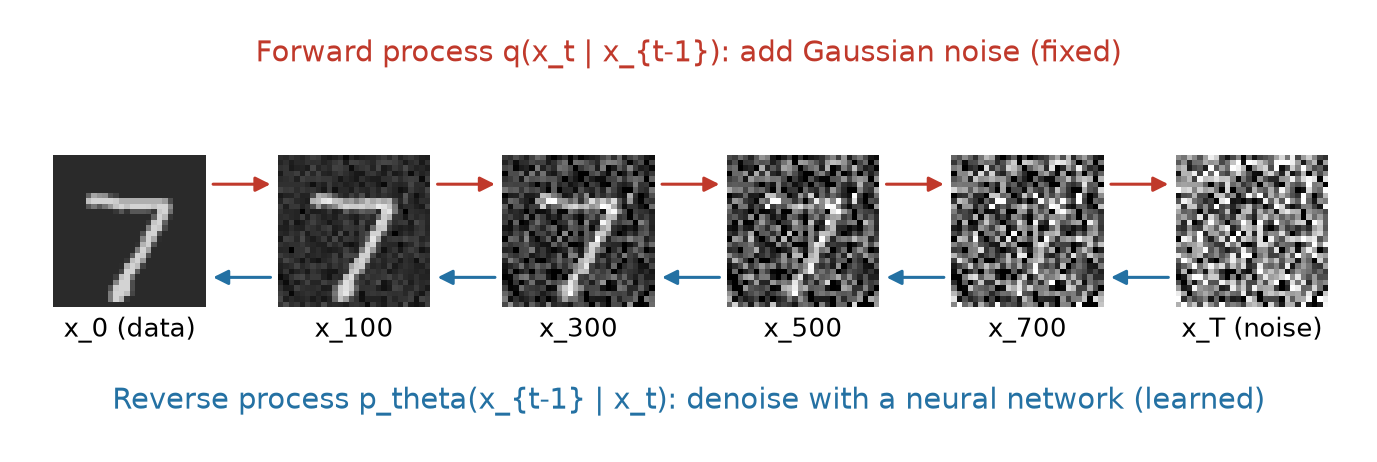

Сверху — прямой процесс $q$: к цифре постепенно добавляется шум, и при $t = T$ от неё ничего не остаётся. Снизу — обратный процесс $p_\theta$: обученная сеть шаг за шагом снимает шум. Прямой процесс не обучается; обучается только обратный.

## 2. Прямой процесс

Прямой процесс — марковская цепь с гауссовыми переходами:

$
q(x_t \mid x_{t-1}) = \mathcal{N}\!\left(x_t;\ \sqrt{1-\beta_t}\,x_{t-1},\ \beta_t I\right), \qquad t = 1, \dots, T.
$

Множитель $\sqrt{1-\beta_t}$ нужен, чтобы дисперсия не росла: если $\mathrm{Var}(x_{t-1}) = 1$, то $\mathrm{Var}(x_t) = (1-\beta_t) + \beta_t = 1$. Поэтому процесс называют variance preserving.

Главное свойство: сумма гауссовых шумов — снова гауссов шум, и к любому шагу можно перейти сразу, без прохода по цепи. Обозначим $\alpha_t = 1 - \beta_t$, $\bar\alpha_t = \prod_{s=1}^{t}\alpha_s$. Тогда

$
q(x_t \mid x_0) = \mathcal{N}\!\left(x_t;\ \sqrt{\bar\alpha_t}\,x_0,\ (1-\bar\alpha_t) I\right), \qquad x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon,\ \ \epsilon \sim \mathcal{N}(0, I).
$

Вывод для двух шагов: $x_2 = \sqrt{\alpha_2}(\sqrt{\alpha_1}x_0 + \sqrt{1-\alpha_1}\epsilon_1) + \sqrt{1-\alpha_2}\epsilon_2$. Шум $\sqrt{\alpha_2(1-\alpha_1)}\epsilon_1 + \sqrt{1-\alpha_2}\epsilon_2$ гауссов с дисперсией $\alpha_2 - \alpha_1\alpha_2 + 1 - \alpha_2 = 1 - \alpha_1\alpha_2$. Дальше по индукции.

Именно замкнутая форма делает обучение дешёвым: на каждой итерации берётся случайный $t$, за одну операцию строится $x_t$, и сеть учится на одном шаге, а не на всей цепи. В DDPM $T = 1000$, а $\beta_t$ растёт линейно от $10^{-4}$ до $0.02$ ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)). При таком расписании $\bar\alpha_T \approx 4 \cdot 10^{-5}$, то есть $x_T$ практически не отличим от $\mathcal{N}(0, I)$. Это проверяется численно в разделе 13.

Удобная единая величина — отношение сигнал/шум $\mathrm{SNR}(t) = \bar\alpha_t / (1-\bar\alpha_t)$. Оно монотонно убывает по $t$, а расписание шума по сути есть выбор кривой $\log \mathrm{SNR}(t)$ (раздел 8).

## 3. Обратный процесс и апостериорное распределение

Генерация идёт в обратную сторону: $x_T \sim \mathcal{N}(0, I)$, затем $x_{t-1} \sim p_\theta(x_{t-1} \mid x_t)$. Истинное обратное распределение $q(x_{t-1} \mid x_t)$ требует знать распределение данных и поэтому недоступно. Но при малых $\beta_t$ оно близко к гауссову, и модель берут гауссовой:

$
p_\theta(x_{t-1} \mid x_t) = \mathcal{N}\!\left(x_{t-1};\ \mu_\theta(x_t, t),\ \sigma_t^2 I\right).
$

Ключ к обучению — распределение $q(x_{t-1} \mid x_t, x_0)$: если дополнительно знать $x_0$, обратный шаг вычисляется точно, по формуле Байеса для гауссиан:

$
q(x_{t-1} \mid x_t, x_0) = \mathcal{N}\!\left(x_{t-1};\ \tilde\mu_t(x_t, x_0),\ \tilde\beta_t I\right),
$
$
\tilde\mu_t = \frac{\sqrt{\bar\alpha_{t-1}}\,\beta_t}{1-\bar\alpha_t}\,x_0 + \frac{\sqrt{\alpha_t}\,(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}\,x_t, \qquad \tilde\beta_t = \frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\,\beta_t.
$

Значит, сети достаточно оценить $x_0$ по $x_t$: подставив оценку $\hat x_0$ в $\tilde\mu_t$, получаем среднее обратного шага. Если выразить $x_0$ через шум, $x_0 = (x_t - \sqrt{1-\bar\alpha_t}\,\epsilon)/\sqrt{\bar\alpha_t}$, среднее записывается через предсказанный шум:

$
\mu_\theta(x_t, t) = \frac{1}{\sqrt{\alpha_t}}\left(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t, t)\right).
$

Дисперсию $\sigma_t^2$ в DDPM не обучали: варианты $\sigma_t^2 = \beta_t$ и $\sigma_t^2 = \tilde\beta_t$ дали похожие результаты ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)). Improved DDPM обучает интерполяцию между ними, что улучшает правдоподобие и позволяет сэмплировать за меньшее число шагов ([Nichol, Dhariwal, 2021](https://proceedings.mlr.press/v139/nichol21a/nichol21a.pdf)).

## 4. Вариационная нижняя граница и $L_{\text{simple}}$

Обратный процесс — модель с латентными переменными $x_{1:T}$, поэтому её обучают так же, как VAE: максимизируют нижнюю границу правдоподобия (ELBO). После перегруппировки слагаемых отрицательная граница распадается на сумму KL-дивергенций:

$
-\log p_\theta(x_0) \le \underbrace{D_{\mathrm{KL}}\big(q(x_T \mid x_0)\,\|\,p(x_T)\big)}_{L_T} + \sum_{t=2}^{T}\underbrace{\mathbb{E}_q\, D_{\mathrm{KL}}\big(q(x_{t-1} \mid x_t, x_0)\,\|\,p_\theta(x_{t-1} \mid x_t)\big)}_{L_{t-1}} \underbrace{-\ \mathbb{E}_q \log p_\theta(x_0 \mid x_1)}_{L_0}.
$

Здесь $L_T$ не зависит от параметров (прямой процесс фиксирован), а каждое $L_{t-1}$ — KL между двумя гауссианами с одинаковой дисперсией, то есть просто квадрат разности средних. Подставляя $\epsilon$-параметризацию, получаем

$
L_{t-1} = \frac{\beta_t^2}{2\sigma_t^2\,\alpha_t\,(1-\bar\alpha_t)}\ \mathbb{E}\,\big\|\epsilon - \epsilon_\theta(x_t, t)\big\|^2 + \text{const}.
$

DDPM отбрасывает вес перед нормой и усредняет по равномерному $t$:

$
L_{\text{simple}} = \mathbb{E}_{t \sim U\{1..T\},\ x_0,\ \epsilon}\ \big\|\epsilon - \epsilon_\theta(\sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\epsilon,\ t)\big\|^2.
$

Это взвешенная вариационная граница, которая по сравнению с настоящей уменьшает вес малых $t$ и позволяет сети сосредоточиться на более трудных шагах с большим шумом ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)). На CIFAR-10 обучение на настоящей границе дало лучшее правдоподобие ($\le 3.70$ бит на измерение), но FID 13.51, а $L_{\text{simple}}$ — FID 3.17 при $\le 3.75$ бит ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)). Хорошее сжатие и хорошие картинки — разные цели.

Полезная переформулировка: вес $L_{t-1}$ при $\sigma_t^2 = \tilde\beta_t$ равен $\tfrac12\big(\mathrm{SNR}(t-1)/\mathrm{SNR}(t) - 1\big)$, то есть вся граница выражается через SNR. В непрерывном пределе VLB зависит от расписания только через значения SNR на концах ([Kingma et al., 2021](https://arxiv.org/abs/2107.00630)). В разделе 14 тождество проверяется численно.

Обучение и генерация DDPM целиком:

| Обучение | Генерация (DDPM) |
|---|---|
| взять $x_0$ из данных, $t \sim U\{1..T\}$, $\epsilon \sim \mathcal{N}(0, I)$ | $x_T \sim \mathcal{N}(0, I)$ |
| $x_t = \sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\epsilon$ | для $t = T, \dots, 1$: $z \sim \mathcal{N}(0, I)$ при $t > 1$, иначе $z = 0$ |
| шаг градиента по $\|\epsilon - \epsilon_\theta(x_t, t)\|^2$ | $x_{t-1} = \mu_\theta(x_t, t) + \sigma_t z$ |

## 5. Что предсказывать: $\epsilon$, $x_0$ или $v$

Поскольку $x_t$ — известная линейная комбинация $x_0$ и $\epsilon$, три цели взаимозаменяемы: зная одну и $x_t$, можно вычислить остальные. Обозначим $a_t = \sqrt{\bar\alpha_t}$, $\sigma_t = \sqrt{1-\bar\alpha_t}$, $a_t^2 + \sigma_t^2 = 1$.

| Цель | Перевод в $\hat x_0$ | Перевод в $\hat\epsilon$ |
|---|---|---|
| $\epsilon$ | $\hat x_0 = (x_t - \sigma_t\hat\epsilon)/a_t$ | — |
| $x_0$ | — | $\hat\epsilon = (x_t - a_t\hat x_0)/\sigma_t$ |
| $v = a_t\epsilon - \sigma_t x_0$ | $\hat x_0 = a_t x_t - \sigma_t \hat v$ | $\hat\epsilon = \sigma_t x_t + a_t \hat v$ |

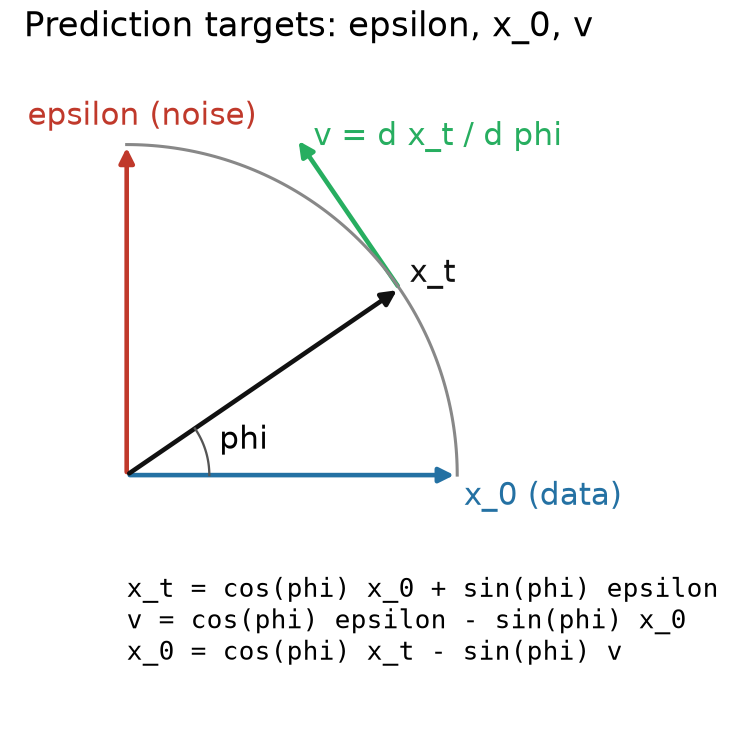

Геометрия: если считать $x_0$ и $\epsilon$ ортогональными единичными векторами, то $x_t = \cos\phi\, x_0 + \sin\phi\, \epsilon$ лежит на дуге окружности, $\phi$ растёт от 0 до $\pi/2$, а $v = dx_t/d\phi$ — касательная к дуге. Отсюда название «скорость» ([Salimans, Ho, 2022](https://arxiv.org/abs/2202.00512)).

Чем они отличаются на практике — масштабом ошибок:

1. $\epsilon$-предсказание: при малом SNR ($a_t \to 0$) ошибка в $\hat\epsilon$ усиливается множителем $\sigma_t/a_t$ при переводе в $\hat x_0$. В конце цепи шум почти равен $x_t$, предсказать его легко, но картинка из него получается плохо.
2. $x_0$-предсказание: при большом SNR ($t \to 0$) ошибка в $\hat x_0$ усиливается множителем $a_t/\sigma_t$ при переводе в $\hat\epsilon$. Сети приходится воспроизводить почти всё изображение, и оценки получаются размытыми.
3. $v$-предсказание: перевод в $\hat x_0$ и $\hat\epsilon$ идёт с коэффициентами не больше 1, поэтому ошибки не раздуваются ни на одном конце. Salimans и Ho ввели её для прогрессивной дистилляции, где $\epsilon$-параметризация при малом числе шагов становится нестабильной; дистиллированная модель даёт FID 3.0 на CIFAR-10 за 4 шага ([Salimans, Ho, 2022](https://arxiv.org/abs/2202.00512)).

Если перевести все три потери в MSE по $x_0$, они отличаются только весом по $t$: $\|\epsilon - \hat\epsilon\|^2 = \mathrm{SNR}(t)\,\|x_0 - \hat x_0\|^2$, $\|v - \hat v\|^2 = (1+\mathrm{SNR}(t))\,\|x_0 - \hat x_0\|^2$. Выбор цели — это выбор взвешивания по уровням шума. В разделе 15 все три цели обучаются на двумерной задаче, где ошибку можно измерить точно.

## 6. Score matching: второй взгляд на ту же модель

Score распределения — это градиент логарифма плотности по данным, $s(x) = \nabla_x \log p(x)$. Он указывает направление, в котором плотность растёт быстрее всего, и не требует нормировочной константы: $\nabla_x \log (\tilde p(x)/Z) = \nabla_x \log \tilde p(x)$. Если score известен, из распределения можно сэмплировать динамикой Ланжевена:

$
x_{k+1} = x_k + \delta\, \nabla_x \log p(x_k) + \sqrt{2\delta}\, z_k, \qquad z_k \sim \mathcal{N}(0, I),
$

которая при малом шаге $\delta$ и большом числе итераций сходится к $p$.

Как обучить сеть $s_\theta(x) \approx \nabla_x \log p(x)$, не зная $p$? Hyvärinen показал, что минимизация $\mathbb{E}\|s_\theta(x) - \nabla_x \log p(x)\|^2$ сводится к выражению, где истинный score не нужен, но нужен след якобиана $s_\theta$ ([Hyvärinen, 2005](https://jmlr.org/papers/v6/hyvarinen05a.html)). Для изображений это слишком дорого. Vincent нашёл более удобный путь — denoising score matching: если зашумить данные, $\tilde x = x + \sigma\epsilon$, то обучение шумоподавляющего автокодировщика эквивалентно score matching для сглаженной плотности, а цель регрессии известна явно: $\nabla_{\tilde x}\log q(\tilde x \mid x) = (x - \tilde x)/\sigma^2$ ([Vincent, 2011](https://www.iro.umontreal.ca/~vincentp/Publications/smdae_techreport.pdf)).

Применим это к диффузии. Для $q(x_t \mid x_0)$ из раздела 2

$
\nabla_{x_t} \log q(x_t \mid x_0) = -\frac{x_t - \sqrt{\bar\alpha_t}x_0}{1-\bar\alpha_t} = -\frac{\epsilon}{\sqrt{1-\bar\alpha_t}},
$

и оптимальный по MSE предсказатель шума даёт score зашумлённых данных:

$
\nabla_{x_t}\log p_t(x_t) = -\frac{\mathbb{E}[\epsilon \mid x_t]}{\sqrt{1-\bar\alpha_t}} \approx -\frac{\epsilon_\theta(x_t, t)}{\sqrt{1-\bar\alpha_t}}.
$

Обучение DDPM на $L_{\text{simple}}$ — это denoising score matching на $T$ уровнях шума сразу. Ho и соавторы отмечают эту связь явно: $\epsilon$-параметризация делает потерю похожей на многоуровневый score matching, а сэмплирование — на динамику Ланжевена ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)).

Зачем много уровней шума. Song и Ermon (NCSN) объяснили, почему одного уровня мало: реальные данные сосредоточены около многообразия низкой размерности, вне которого плотность почти нулевая и score оценивается плохо, а Ланжевен медленно переходит между модами. Решение — оценивать score на последовательности убывающих уровней шума и запускать отжиговую (annealed) динамику Ланжевена от большого шума к малому; на CIFAR-10 это дало Inception Score 8.87 ([Song, Ermon, 2019](https://arxiv.org/abs/1907.05600)). В разделе 16 обе версии сравниваются на точном score смеси гауссиан: одноуровневый Ланжевен «застревает» в стартовых модах и неправильно распределяет массу.

## 7. Непрерывное время: SDE, обратная SDE и probability flow ODE

Если число шагов $T \to \infty$, а $\beta_t \to 0$, цепь DDPM превращается в стохастическое дифференциальное уравнение. Для variance preserving процесса

$
dx = -\tfrac12 \beta(t)\, x\, dt + \sqrt{\beta(t)}\, dW, \qquad t \in [0, 1].
$

Song и соавторы показали, что у любой такой SDE есть обратная по времени SDE, и в неё входит только score зашумлённых распределений ([Song et al., 2021](https://arxiv.org/abs/2011.13456)):

$
dx = \left[-\tfrac12\beta(t)\,x - \beta(t)\,\nabla_x \log p_t(x)\right]dt + \sqrt{\beta(t)}\, d\bar W.
$

Обучив $s_\theta(x, t)$ (или, что то же, $\epsilon_\theta$), можно численно решать обратную SDE от шума к данным. Шаг DDPM — это одна из дискретизаций этой SDE.

Кроме того, у той же SDE есть детерминированное обыкновенное дифференциальное уравнение — probability flow ODE, траектории которого дают те же маргинальные распределения $p_t$:

$
\frac{dx}{dt} = -\tfrac12\beta(t)\left[x + \nabla_x\log p_t(x)\right].
$

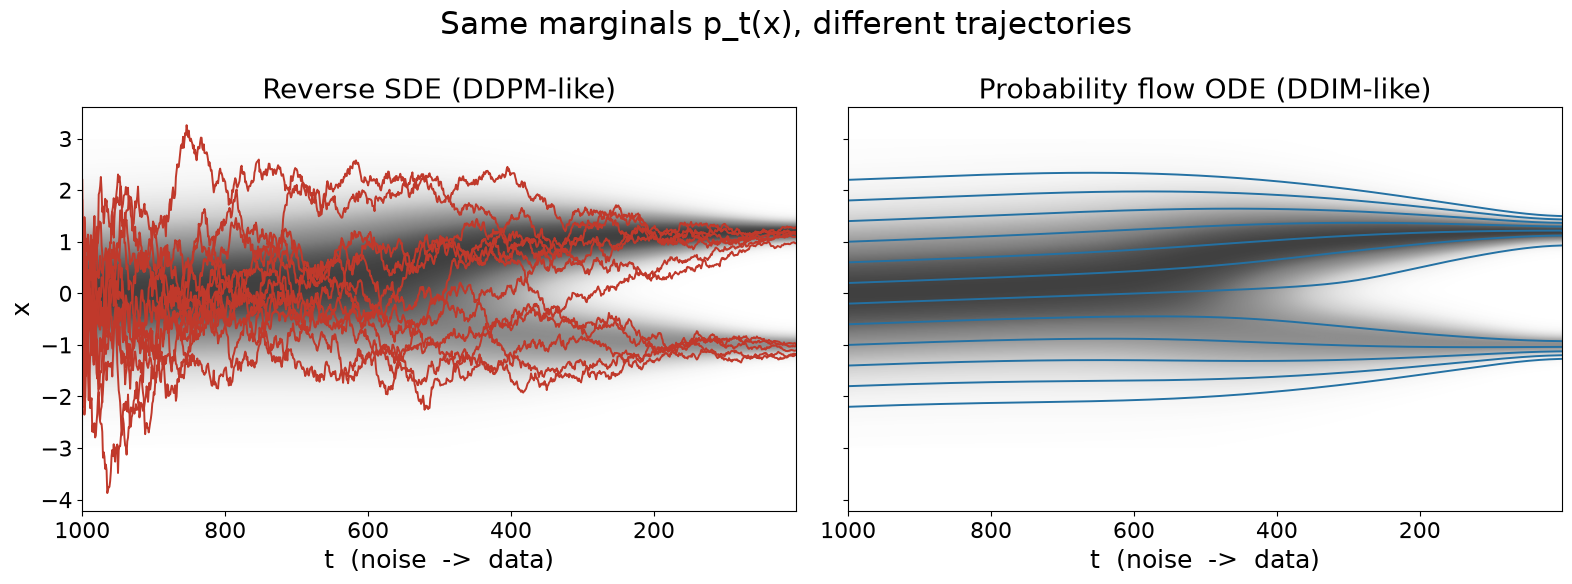

На рисунке одномерный пример со смесью двух гауссиан, где score вычисляется точно. Цветом показана плотность $p_t(x)$, время идёт справа налево (от шума к данным). Траектории обратной SDE (слева) дрожат и могут пересекаться, траектории ODE (справа) гладкие, не пересекаются, и каждая стартовая точка шума однозначно переходит в свой образец. При этом распределение конечных точек у обоих одинаково.

Что даёт ODE:

1. Детерминированное отображение «шум — изображение»: один и тот же $x_T$ всегда даёт одну и ту же картинку, можно интерполировать в пространстве шума и обращать изображение в шум.
2. Точное правдоподобие через формулу замены переменных, как в нормализующих потоках. В работе Score SDE это дало 2.99 бит на измерение на CIFAR-10, а вместе с архитектурными улучшениями — FID 2.20 и генерацию изображений 1024×1024 ([Song et al., 2021](https://arxiv.org/abs/2011.13456)).
3. Возможность использовать адаптивные ODE-решатели высокого порядка с малым числом шагов. EDM, систематизировав выбор расписания, параметризации и решателя, получила FID 1.79 на CIFAR-10 за 35 вызовов сети ([Karras et al., 2022](https://arxiv.org/abs/2206.00364)).

Score SDE предлагает также схему predictor-corrector: шаг решателя обратной SDE (предиктор) чередуется с несколькими шагами Ланжевена на текущем уровне шума (корректор), который исправляет накопленную ошибку ([Song et al., 2021](https://arxiv.org/abs/2011.13456)).

### DDIM как дискретизация ODE

DDIM пришёл к детерминированной генерации с другой стороны. Потеря $L_{\text{simple}}$ зависит только от маргиналов $q(x_t \mid x_0)$, а не от того, как устроена цепь. Поэтому можно взять немарковский прямой процесс с теми же маргиналами и получить семейство обратных шагов, для которых подходит та же обученная сеть ([Song, Meng, Ermon, 2021](https://arxiv.org/abs/2010.02502)):

$
x_{t'} = \sqrt{\bar\alpha_{t'}}\,\hat x_0 + \sqrt{1-\bar\alpha_{t'} - \sigma^2}\;\hat\epsilon + \sigma z, \qquad \hat x_0 = \frac{x_t - \sqrt{1-\bar\alpha_t}\,\hat\epsilon}{\sqrt{\bar\alpha_t}},
$

$
\sigma = \eta\,\sqrt{\frac{1-\bar\alpha_{t'}}{1-\bar\alpha_t}}\sqrt{1-\frac{\bar\alpha_t}{\bar\alpha_{t'}}}.
$

Здесь $t' < t$ — следующий шаг, не обязательно $t-1$. При $\eta = 1$ и $t' = t-1$ это DDPM, при $\eta = 0$ — детерминированный шаг, который является дискретизацией probability flow ODE. Шаги можно пропускать: авторы получают образцы того же качества в 10–50 раз быстрее, чем DDPM ([Song, Meng, Ermon, 2021](https://arxiv.org/abs/2010.02502)). Интуиция формулы: «оценить чистое изображение, затем снова зашумить его до уровня $t'$, используя тот же предсказанный шум». В практикуме этот сэмплер реализован одной функцией с параметром $\eta$, и DDPM получается как его частный случай.

| Сэмплер | Стохастичность | Типичное NFE | Детерминирован по $x_T$ |
|---|---|---|---|
| DDPM (ancestral) | $\eta = 1$ | 1000 | нет |
| DDIM | $\eta = 0$ | 25–100 | да |
| Решатели ODE (Heun в EDM и др.) | нет | 10–40 | да |
| Predictor-corrector | да | 1000 и больше | нет |
| Дистилляция (progressive, consistency) | — | 1–8 | да |

## 8. Расписания шума

Расписание $\{\beta_t\}$ задаёт, как быстро сигнал заменяется шумом, а эквивалентно — кривую $\log\mathrm{SNR}(t)$. От неё зависит, сколько шагов обучения и генерации приходится на «интересные» уровни шума.

Линейное расписание DDPM ($\beta_t$ от $10^{-4}$ до $0.02$) разрушает изображение слишком быстро. Nichol и Dhariwal заметили, что для изображений 64×64 и 32×32 конец прямого процесса слишком шумный и мало добавляет к качеству: при линейном расписании можно пропустить до 20% обратного процесса почти без потери FID ([Nichol, Dhariwal, 2021](https://proceedings.mlr.press/v139/nichol21a/nichol21a.pdf)). Они предложили косинусное расписание

$
\bar\alpha_t = \frac{f(t)}{f(0)}, \qquad f(t) = \cos^2\!\left(\frac{t/T + s}{1+s}\cdot\frac{\pi}{2}\right), \qquad s = 0.008,
$

где $\beta_t = 1 - \bar\alpha_t/\bar\alpha_{t-1}$ ограничивается сверху значением 0.999, чтобы избежать сингулярности при $t \to T$. Смещение $s$ подобрано так, чтобы $\sqrt{\beta_0}$ было чуть меньше шага квантования пикселя $1/127.5$ ([Nichol, Dhariwal, 2021](https://proceedings.mlr.press/v139/nichol21a/nichol21a.pdf)). В середине процесса $\bar\alpha_t$ у косинусного расписания убывает почти линейно, а $\log\mathrm{SNR}$ — почти равномерно, без длинного «хвоста» чистого шума.

Три практических наблюдения:

1. Правильное расписание зависит от разрешения. Изображение большего размера содержит больше избыточности, и при том же $\beta_t$ его крупная структура разрушается позже; для высоких разрешений расписание нужно сдвигать в сторону большего шума ([Hoogeboom et al., 2023](https://arxiv.org/abs/2301.11093)).
2. Конечный SNR должен быть нулевым. У многих расписаний $\bar\alpha_T > 0$, и при обучении сеть видит в $x_T$ остаток сигнала (в частности, среднюю яркость), а при генерации стартует с чистого шума. Lin и соавторы показали, что из-за этого Stable Diffusion генерирует изображения только средней яркости, и предложили перемасштабировать расписание до нулевого терминального SNR, перейти на $v$-предсказание (при SNR = 0 $\epsilon$-предсказание вырождается), всегда начинать сэмплирование с последнего шага и перемасштабировать CFG ([Lin et al., 2024](https://arxiv.org/abs/2305.08891)).
3. В непрерывном времени ELBO инвариантна к форме расписания между концами ([Kingma et al., 2021](https://arxiv.org/abs/2107.00630)), но $L_{\text{simple}}$ и сэмплеры с малым числом шагов — нет. Поэтому выбор расписания влияет прежде всего на качество образцов и на то, как распределены по $t$ шаги сэмплера.

Современная тенденция — выбирать не $\beta_t$, а плотность, с которой при обучении сэмплируется уровень шума. В Stable Diffusion 3 используется rectified flow (прямая линия между данными и шумом, $x_t = (1-t)x_0 + t\epsilon$) и сэмплирование $t$ со смещением к средним, перцептивно важным уровням шума ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)).

## 9. Архитектуры денойзера

Сеть $\epsilon_\theta(x_t, t, y)$ должна принимать изображение и выдавать тензор того же размера, а также учитывать уровень шума $t$ и условие $y$. Изображение на выходе того же размера — задача, для которой хорошо подходит U-Net.

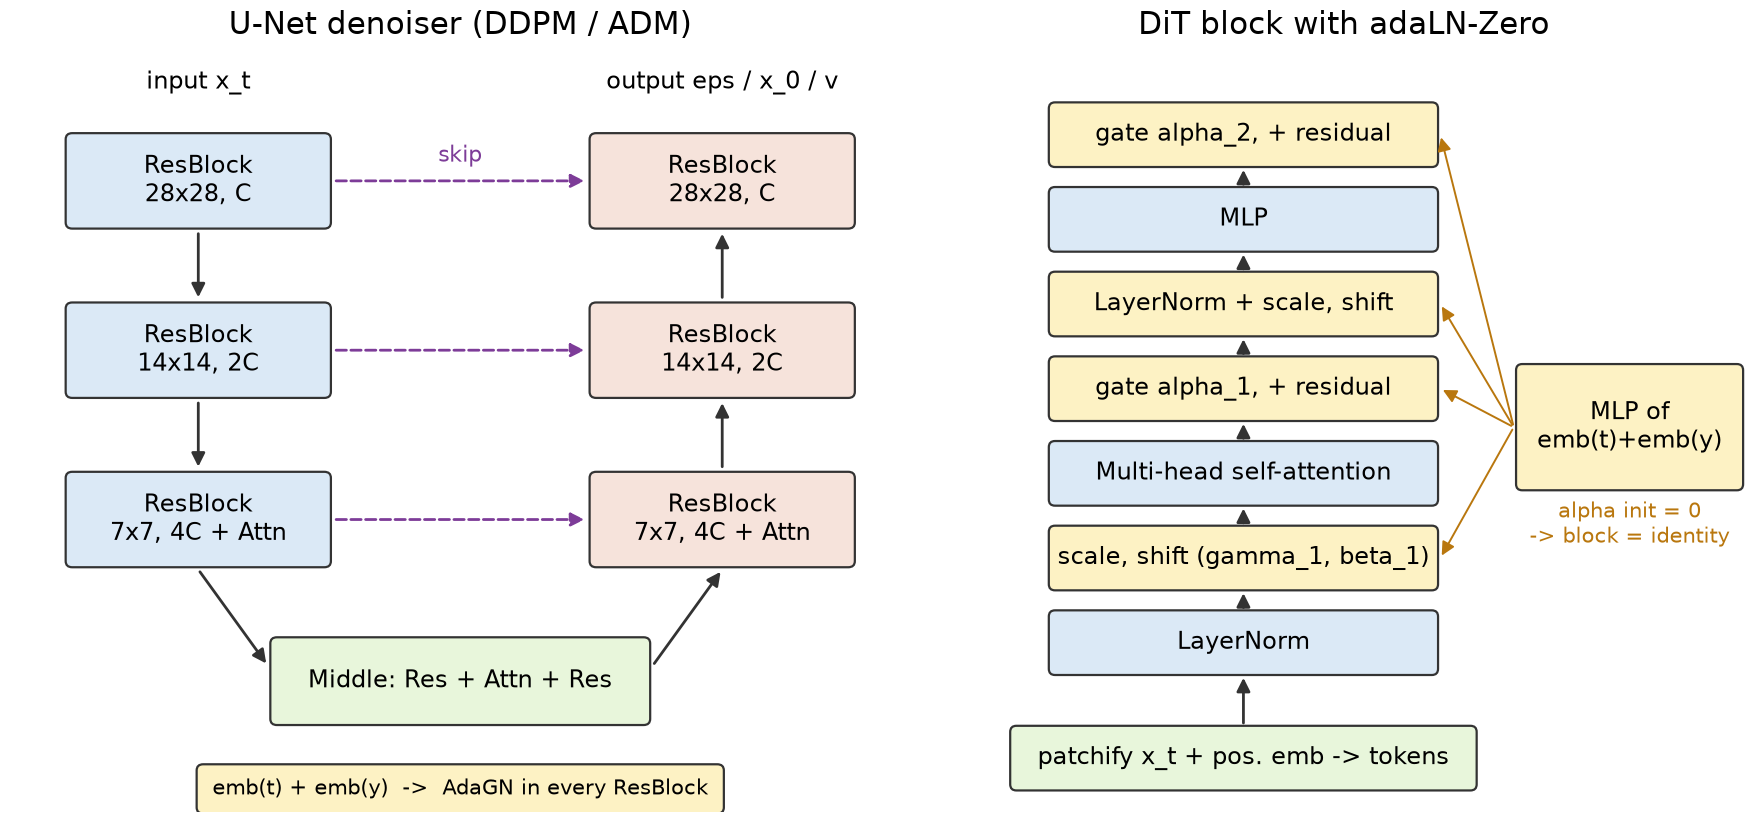

### U-Net с timestep embedding

U-Net — энкодер-декодер со skip-соединениями между уровнями одинакового разрешения; предложен для сегментации медицинских изображений ([Ronneberger et al., 2015](https://arxiv.org/abs/1505.04597)). В DDPM используется U-Net в стиле PixelCNN++ без маскирования, с групповой нормализацией, self-attention на разрешении 16×16 и синусоидальным кодированием времени, как позиционное кодирование трансформера; модель для CIFAR-10 имеет 35.7 млн параметров ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)).

Timestep embedding устроен так:

$
\mathrm{emb}(t)_{2i} = \sin(t\,\omega_i), \quad \mathrm{emb}(t)_{2i+1} = \cos(t\,\omega_i), \quad \omega_i = 10000^{-2i/d},
$

после чего вектор проходит через MLP и подаётся в каждый остаточный блок. ADM (Dhariwal, Nichol) использует адаптивную групповую нормализацию $\mathrm{AdaGN}(h, y) = y_s\,\mathrm{GroupNorm}(h) + y_b$, где $y_s, y_b$ — линейная проекция суммы эмбеддингов времени и класса ([Dhariwal, Nichol, 2021](https://arxiv.org/abs/2105.05233)). Так один набор свёрток работает на всех уровнях шума: при большом $t$ сеть восстанавливает грубую структуру, при малом — детали.

Важные детали: выходной слой инициализируется нулями (сеть стартует с $\hat\epsilon = 0$), а для генерации используются веса экспоненциального скользящего среднего (EMA) параметров. Оба приёма реализованы в практикуме (разделы 17–18).

### DiT: диффузионный трансформер

DiT заменяет U-Net обычным ViT на латентах. Вход разбивается на патчи размера $p$, число токенов равно $(I/p)^2$; авторы рассматривают $p \in \{2, 4, 8\}$ ([Peebles, Xie, 2023](https://arxiv.org/abs/2212.09748)). Условие (время и класс) вводится через adaLN-Zero: эмбеддинг $c = \mathrm{emb}(t) + \mathrm{emb}(y)$ через MLP даёт параметры сдвига $\beta$, масштаба $\gamma$ и затвора $\alpha$ для LayerNorm перед attention и MLP:

$
h \leftarrow h + \alpha_1 \cdot \mathrm{Attn}\big(\gamma_1 \cdot \mathrm{LN}(h) + \beta_1\big), \qquad h \leftarrow h + \alpha_2 \cdot \mathrm{MLP}\big(\gamma_2 \cdot \mathrm{LN}(h) + \beta_2\big).
$

Линейный слой, выдающий $\alpha$, инициализируется нулями, поэтому каждый блок в начале обучения — тождественное отображение. Авторы сравнили adaLN-Zero с in-context условием (дополнительные токены) и cross-attention, и adaLN-Zero оказался лучше по FID и дешевле ([Peebles, Xie, 2023](https://arxiv.org/abs/2212.09748)).

Главный результат DiT — масштабируемость: FID монотонно падает с ростом Gflops модели, а DiT-XL/2 (675 млн параметров, 118.6 Gflops, латент 32×32×4 для изображений 256×256) получил FID 2.27 на ImageNet 256×256 с CFG 1.5 ([Peebles, Xie, 2023](https://arxiv.org/abs/2212.09748)). Отсюда трансформерные денойзеры в Stable Diffusion 3 (MM-DiT с раздельными весами для текста и изображения) ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)).

| | U-Net (ADM) | DiT |
|---|---|---|
| Индуктивные смещения | локальные свёртки, многомасштабность, skip-соединения | только патчи и позиционные эмбеддинги |
| Условие по $t$, $y$ | AdaGN в каждом ResBlock | adaLN-Zero в каждом блоке |
| Вычисления | зависят от разрешения и числа уровней | $\propto (I/p)^2$ токенов, квадратично в attention |
| Сильная сторона | эффективна на малых данных и пикселях | предсказуемо масштабируется, удобна для мультимодальности |

## 10. Условная генерация и guidance

Условная модель $\epsilon_\theta(x_t, t, y)$ получает класс или текст и генерирует $p(x \mid y)$. На практике выборки из «честного» $p(x \mid y)$ часто недостаточно похожи на условие, и качество улучшают, смещая выборку к областям, где условие выполняется увереннее. Это и есть guidance.

### Classifier guidance

По формуле Байеса $\nabla_x \log p_t(x \mid y) = \nabla_x \log p_t(x) + \nabla_x \log p_t(y \mid x)$. Dhariwal и Nichol обучают отдельный классификатор $p_\phi(y \mid x_t, t)$ на зашумлённых изображениях и добавляют масштабированный градиент его логарифма к шагу сэмплера ([Dhariwal, Nichol, 2021](https://arxiv.org/abs/2105.05233)). Для DDIM это записывается через предсказанный шум:

$
\hat\epsilon = \epsilon_\theta(x_t, t) - s\,\sqrt{1-\bar\alpha_t}\ \nabla_{x_t}\log p_\phi(y \mid x_t, t).
$

Масштаб $s$ соответствует выборке из $p(x)\,p(y \mid x)^s$: при $s > 1$ распределение сосредотачивается на модах классификатора, образцы становятся более «типичными» и менее разнообразными ([Dhariwal, Nichol, 2021](https://arxiv.org/abs/2105.05233)). С этой техникой ADM получила FID 2.97, 4.59 и 7.72 на ImageNet 128, 256 и 512 и сравнялась с BigGAN-deep, используя всего 25 прямых проходов на образец ([Dhariwal, Nichol, 2021](https://arxiv.org/abs/2105.05233)).

Недостатки: нужен отдельный классификатор, обученный на шумных данных (готовый классификатор на чистых изображениях не годится), а его градиенты могут быть «адверсариальными» — улучшать уверенность классификатора, а не изображение.

### Classifier-free guidance

Ho и Salimans убрали классификатор. Одна сеть обучается и как условная, и как безусловная: с вероятностью $p_{\text{uncond}}$ условие при обучении заменяется на пустой токен $\varnothing$. При генерации два предсказания комбинируются ([Ho, Salimans, 2022](https://arxiv.org/abs/2207.12598)):

$
\tilde\epsilon = (1+w)\,\epsilon_\theta(x_t, y) - w\,\epsilon_\theta(x_t, \varnothing) = \epsilon_\theta(x_t, y) + w\,\big(\epsilon_\theta(x_t, y) - \epsilon_\theta(x_t, \varnothing)\big).
$

В терминах score это неявный классификатор: $\epsilon(x, y) - \epsilon(x, \varnothing) \propto -\nabla_x \log p(y \mid x)$, то есть CFG — classifier guidance с «классификатором», полученным по Байесу из самой генеративной модели. При $w = 0$ получаем обычную условную модель, при $w > 0$ — выборку, приближённо пропорциональную $p(x \mid y)\,p(y \mid x)^w$.

В экспериментах на ImageNet значения $p_{\text{uncond}} = 0.1$ и $0.2$ работали одинаково хорошо, а $0.5$ — хуже; лучший FID достигался при малой силе $w = 0.1\text{–}0.3$ (FID 2.43 при $w = 0.3$ на 128×128), а лучший Inception Score — при $w \ge 4$ ([Ho, Salimans, 2022](https://arxiv.org/abs/2207.12598)). Цена CFG — два прохода сети на шаг (условный и безусловный обычно объединяют в один батч).

Обратите внимание на соглашение: в статье Ho и Salimans $w = 0$ означает условную модель без усиления. В Stable Diffusion и diffusers используется масштаб $g = 1 + w$, и «guidance scale 7.5» соответствует $w = 6.5$. В лекции 11 CFG для авторегрессии записывался через логиты; формула та же, только вместо $\epsilon$ — логарифмы вероятностей токенов.

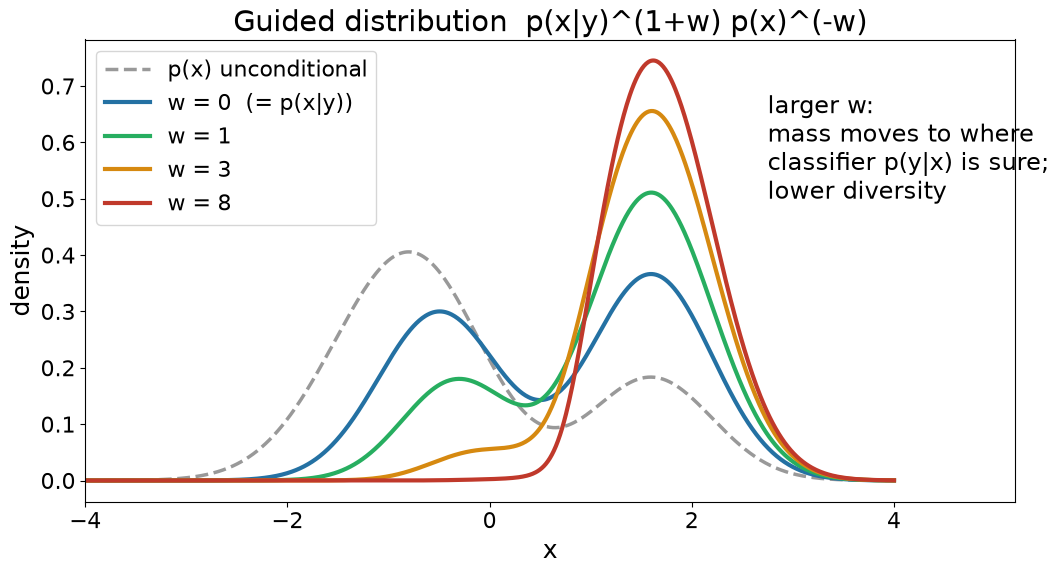

### Компромисс fidelity–diversity

С ростом $w$ (или $s$) образцы становятся чётче и сильнее соответствуют условию (выше точность классификатора и его уверенность, выше IS), но теряют разнообразие и в конце концов насыщаются и искажаются. FID, который измеряет и качество, и покрытие распределения, сначала падает, затем растёт — у него U-образная зависимость от $w$. Ho и Salimans сравнивают этот эффект с truncation trick в GAN и низкой температурой в авторегрессионных моделях ([Ho, Salimans, 2022](https://arxiv.org/abs/2207.12598)). Это та же ось трилеммы генеративных моделей (качество, разнообразие, скорость), что обсуждалась в лекции 11 ([Xiao et al., 2022](https://arxiv.org/abs/2112.07804)).

На рисунке выше показан одномерный пример. Класс $y$ имеет две моды; левая перекрывается с другим классом (там $p(y \mid x)$ мало), правая принадлежит только классу $y$. Усиленные распределения $\propto p(x \mid y)^{1+w}\,p(x)^{-w} \propto p(x \mid y)\,p(y \mid x)^{w}$ с ростом $w$ переносят массу в правую моду, где «классификатор» уверен, а неоднозначная левая мода исчезает: точность соответствия классу растёт, разнообразие падает. В разделах 20 и 21 этот эффект измеряется на MNIST.

## 11. Сэмплинг, оценка и практика

Оценка качества. Основная метрика — FID: расстояние Фреше между гауссовыми приближениями признаков Inception-v3 для реальных и сгенерированных изображений ([Heusel et al., 2017](https://arxiv.org/abs/1706.08500)). Он чувствителен и к качеству, и к разнообразию, но зависит от размера выборки и признакового экстрактора, поэтому значения FID сравнимы только при одинаковом протоколе. Дополнительно используют IS, precision/recall и CLIP score для текстовых моделей. В практикуме вместо Inception используется небольшой классификатор MNIST: из его признаков вычисляется FD (аналог FID), а из его предсказаний — точность соответствия классу, уверенность и разнообразие.

Латентная диффузия. Диффузия в пикселях дорогая: каждый шаг обрабатывает полное изображение. Latent Diffusion сначала сжимает изображение автокодировщиком (VAE с небольшой регуляризацией KL или VQ) и проводит диффузию в латентном пространстве, а текстовое условие вводит через cross-attention; так устроена Stable Diffusion ([Rombach et al., 2022](https://arxiv.org/pdf/2112.10752)). Токенизатор из лекции 11 и денойзер из этой лекции — две половины такой системы.

Типичные ошибки:

1. Расхождение расписания при обучении и генерации (например, обучили на косинусном, а сэмплер вычисляет $\bar\alpha_t$ по линейному). Образцы получаются пересвеченными или шумными.
2. Нормализация данных: модель ожидает $x_0 \in [-1, 1]$, а на вход подаётся $[0, 1]$. Дисперсия сигнала тогда не согласована с шумом.
3. Индексация $t$: смещение на единицу между $t$ в обучении ($1..T$ или $0..T-1$) и в сэмплере.
4. Отсутствие EMA: веса без усреднения дают заметно худшие образцы при той же потере.
5. Начало сэмплирования не с последнего шага (например, $t = 980$ при сетке DDIM, равномерной от нуля) или ненулевой терминальный SNR — модель недополучает или переполучает «сигнал» на старте ([Lin et al., 2024](https://arxiv.org/abs/2305.08891)).
6. Обрезка $\hat x_0$ до $[-1, 1]$ отключена при малом числе шагов — образцы могут уходить за допустимый диапазон.
7. Слишком сильный guidance: высокий $w$ выглядит «красиво» на нескольких образцах, но в метриках проявляется как падение разнообразия и рост FID.

# Часть II. Практикум

## 12. Подготовка: среда, данные, модель-оценщик

### 12.1. Задача практикума

Практикум проходит лекцию в двух масштабах. Двумерные игрушечные данные (смесь гауссиан) позволяют увидеть то, что на изображениях скрыто: точный score зашумлённого распределения известен аналитически, поэтому можно сравнить с ним выученный, нарисовать векторное поле и траектории SDE и ODE. Изображения — MNIST 28×28 ([LeCun et al.](https://yann.lecun.org/exdb/mnist/index.html)). На нём обучаются U-Net и DiT, сравниваются сэмплеры, classifier guidance и classifier-free guidance, линейное и косинусное расписания шума.

| Раздел | Что делаем | Что увидим |
|---|---|---|
| 12 | среда, данные, классификатор-оценщик | FD, точность класса, разнообразие |
| 13 | прямой процесс и расписания шума | $\bar\alpha_t$, log-SNR, замкнутая формула $q(x_t \mid x_0)$ |
| 14 | апостериорное распределение и веса ELBO | почему $L_{\text{simple}}$ — это перевзвешенная граница |
| 15 | 2D: параметризации $\epsilon$, $x_0$, $v$ и score | ошибка по уровням шума, сравнение с точным score |
| 16 | 2D: SDE, ODE, Langevin | стохастические и детерминированные траектории, веса мод |
| 17 | U-Net с timestep embedding | синусоидальное кодирование времени, AdaGN |
| 18 | обучение DDPM на MNIST | кривая потерь, предсказание $x_0$ из шума |
| 19 | сэмплеры: DDPM и DDIM, число шагов | качество против времени |
| 20 | classifier-free guidance | компромисс fidelity–diversity |
| 21 | classifier guidance | шумный классификатор, градиент по $x_t$ |
| 22 | DiT-mini, линейное и косинусное расписания | adaLN-Zero, пропуск начала обратного процесса |
| 23 | сводная таблица | всё в одних метриках |

### 12.2. Режимы запуска

В Colab с GPU (`Runtime → Change runtime type → T4 GPU`) модели шире (U-Net с 64 базовыми каналами и двумя блоками на уровень вместо 16 и одного, DiT с $d = 256$, 8 блоками и патчем 2 вместо $d = 128$, 4 блоков и патча 4) и обучаются в 6 раз дольше, а для оценки генерируется 1000 изображений. На CPU автоматически включается `FAST_DEV_RUN`: шагов обучения в несколько раз меньше, сети уже, для оценки генерируется 200 изображений. Все числа в тексте практикума взяты из сохранённого CPU-прогона. На GPU значения будут другими (как правило, лучше), поэтому переносить стоит направление эффектов, а не сами числа. GPU-путь не проверялся.

In [1]:
import os, io, math, time, random, platform
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from scipy import linalg

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FAST_DEV_RUN = DEVICE == "cpu"
torch.set_num_threads(max(1, os.cpu_count() or 1))

S = dict(  # шаги оптимизатора, размеры сетей и оценочных выборок
    bs=128, steps_cls=500, steps_2d=4000, ch=64, mult=(1, 2, 2), n_res=2, drop=0.1, steps_unet=15000,
    steps_ncls=3000, dit_d=256, dit_depth=8, dit_patch=2, steps_dit=15000, n_eval=1000)
if FAST_DEV_RUN:
    S.update(bs=64, steps_cls=800, steps_2d=2500, ch=16, mult=(1, 2, 4), n_res=1, drop=0.0, steps_unet=2400,
             steps_ncls=1000, dit_d=128, dit_depth=4, dit_patch=4, steps_dit=2400, n_eval=200)

def seed_all(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all(0)

print("python", platform.python_version(), "| torch", torch.__version__, "| torchvision", torchvision.__version__)
print("device:", DEVICE, "| FAST_DEV_RUN:", FAST_DEV_RUN, "| threads:", torch.get_num_threads())
print(S)

python 3.12.13 | torch 2.14.1+cpu | torchvision 0.29.1+cpu
device: cpu | FAST_DEV_RUN: True | threads: 2
{'bs': 64, 'steps_cls': 800, 'steps_2d': 2500, 'ch': 16, 'mult': (1, 2, 4), 'n_res': 1, 'drop': 0.0, 'steps_unet': 2400, 'steps_ncls': 1000, 'dit_d': 128, 'dit_depth': 4, 'dit_patch': 4, 'steps_dit': 2400, 'n_eval': 200}


### 12.3. Данные

MNIST: 60 000 обучающих и 10 000 тестовых изображений 28×28. Размер 28 делится на 4: этого хватает для трёх уровней U-Net (28 → 14 → 7) и патчей DiT размера 2 и 4. Диффузионные модели обучаются на значениях в $[-1, 1]$: тогда данные и шум $\mathcal{N}(0, I)$ имеют сопоставимый масштаб. Классификатор-оценщик работает в $[0, 1]$, функции `to_m1` и `to_01` переводят одно в другое.

train (60000, 1, 28, 28) test (10000, 1, 28, 28)


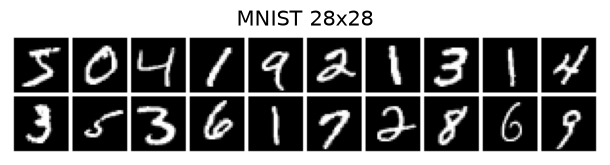

In [2]:
tr = torchvision.datasets.MNIST("data", train=True, download=True)
te = torchvision.datasets.MNIST("data", train=False, download=True)
def to_tensor(ds):
    return ds.data.float().div(255).unsqueeze(1), ds.targets.clone()
Xtr, Ytr = to_tensor(tr); Xte, Yte = to_tensor(te)
to_m1 = lambda x: x * 2 - 1
to_01 = lambda x: ((x + 1) / 2).clamp(0, 1)
print("train", tuple(Xtr.shape), "test", tuple(Xte.shape))

def batches(X, Y, bs, steps, seed=0):
    g = torch.Generator().manual_seed(seed)
    for _ in range(steps):
        i = torch.randint(0, len(X), (bs,), generator=g)
        yield X[i].to(DEVICE), Y[i].to(DEVICE)

def show(imgs, nrow=10, title=None, scale=1.0):
    imgs = imgs.detach().float().cpu().clamp(0, 1)
    ncol = math.ceil(len(imgs) / nrow)
    grid = torchvision.utils.make_grid(imgs, nrow=nrow, padding=2, pad_value=1.0)
    plt.figure(figsize=(scale * nrow * 0.62, scale * ncol * 0.62 + (0.5 if title else 0)))
    plt.imshow(grid.permute(1, 2, 0).numpy(), cmap="gray"); plt.axis("off")
    if title: plt.title(title, fontsize=15)
    plt.tight_layout(); plt.show()

class Timer:
    def __enter__(self):
        if torch.cuda.is_available(): torch.cuda.synchronize()
        self.t = time.time(); return self
    def __exit__(self, *a):
        if torch.cuda.is_available(): torch.cuda.synchronize()
        self.s = time.time() - self.t

show(Xtr[:20], title="MNIST 28x28")

### 12.4. Классификатор-оценщик и метрики генерации

Генеративные модели сравниваются тремя числами. Все три считает один маленький классификатор, обученный на реальных данных.

- FD (Fréchet distance) — расстояние Фреше между гауссианами, подогнанными к признакам реальных и сгенерированных изображений. Формула та же, что у FID ([Heusel et al., 2017](https://arxiv.org/abs/1706.08500)), но признаки берутся из нашего классификатора, а не из Inception. Числа несравнимы с FID из статей, но сравнимы между моделями блокнота. Меньше — лучше.
- Точность класса (acc) — доля изображений, которые классификатор относит к запрошенному классу. Это мера соответствия условию (fidelity в смысле условной генерации).
- Разнообразие (div) — средняя попарная дистанция признаков внутри класса, делённая на ту же величину для реальных изображений. Значение 1 — «разнообразно, как реальные данные», около 0 — «одно и то же изображение».

Вспомогательная величина — уверенность классификатора (conf, средняя максимальная вероятность): неразборчивые цифры дают низкую уверенность.

In [3]:
class Clf(nn.Module):
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.head = nn.Linear(128, 10)
    def forward(self, x): return self.head(self.f(x))

seed_all(0)
clf = Clf().to(DEVICE); opt = torch.optim.Adam(clf.parameters(), 2e-3)
with Timer() as t:
    for x, y in batches(Xtr, Ytr, S["bs"], S["steps_cls"], seed=1):
        loss = F.cross_entropy(clf(x), y); opt.zero_grad(); loss.backward(); opt.step()
clf.eval().requires_grad_(False)

@torch.no_grad()
def clf_out(x, bs=500):
    fs, ps = [], []
    for i in range(0, len(x), bs):
        xb = x[i:i + bs].to(DEVICE).float().clamp(0, 1)
        f = clf.f(xb); fs.append(f.cpu()); ps.append(clf.head(f).softmax(-1).cpu())
    return torch.cat(fs).double().numpy(), torch.cat(ps)

def frechet(fa, fb):
    mu1, mu2 = fa.mean(0), fb.mean(0); s1, s2 = np.cov(fa, rowvar=False), np.cov(fb, rowvar=False)
    covmean = linalg.sqrtm(s1 @ s2)
    if isinstance(covmean, tuple): covmean = covmean[0]
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean.real))

def within_class_spread(f, cls):
    vals = []
    for c in range(10):
        fc = torch.from_numpy(f[cls == c])
        if len(fc) >= 2: vals.append(torch.pdist(fc).mean().item())
    return float(np.mean(vals))

F_TE, P_TE = clf_out(Xte)
print(f"classifier: {t.s:.0f} s, test accuracy {(P_TE.argmax(1) == Yte).float().mean():.4f}")
g = torch.Generator().manual_seed(0)
REF_IDX = torch.randperm(len(Xte), generator=g)[:S["n_eval"]]
SPREAD_REAL = within_class_spread(F_TE[REF_IDX], Yte[REF_IDX].numpy())

def evaluate(x01, y=None):
    """x01 в [0, 1]. FD к 10 000 тестовых изображений, acc (если задан класс), conf, div."""
    f, p = clf_out(x01); pred = p.argmax(1)
    cls = (y.cpu() if y is not None else pred).numpy()
    r = dict(FD=frechet(f, F_TE), conf=p.max(1).values.mean().item(),
             div=within_class_spread(f, cls) / SPREAD_REAL)
    if y is not None: r["acc"] = (pred == y.cpu()).float().mean().item()
    return r

def fmt(r): return "  ".join(f"{k}={v:.3f}" if k != "FD" else f"FD={v:.2f}" for k, v in r.items())
base_real = evaluate(Xte[REF_IDX], Yte[REF_IDX])
print("real test sample:", fmt(base_real))
Y_EVAL = torch.arange(S["n_eval"]) % 10           # запрашиваемые классы при оценке: поровну каждой цифры

classifier: 23 s, test accuracy 0.9449


real test sample: FD=3.04  conf=0.924  div=1.000  acc=0.940


/tmp/ipykernel_6207/378444187.py:28: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


Что видно. Классификатор за 800 шагов достигает точности 94,5% на тесте; этого достаточно, чтобы различать цифры, но это не эталонная сеть. 200 случайных настоящих тестовых изображений дают FD = 3,04 относительно всех 10 000 тестовых, acc = 0,94, conf = 0,92, div = 1 (по определению). Значение FD около 3 — это «пол» метрики при выборке из 200 изображений: даже реальные данные не дают нуля, поэтому разница в FD меньше 1–2 между моделями блокнота не значима. Предупреждение `LinAlgWarning` о сингулярной матрице появляется по той же причине: 200 образцов мало для оценки ковариации 128-мерных признаков.

## 13. Прямой процесс и расписания шума

### 13.1. Класс `Schedule`

Всё, что нужно прямому и обратному процессам, вычисляется из последовательности $\beta_1, \dots, \beta_T$ (раздел 2). В коде индекс сдвинут на единицу: элемент `ab[i]` — это $\bar\alpha_{i+1}$, так что `t = 0` — первый, слабо зашумлённый шаг, а `t = T - 1` — последний. Два расписания:

- линейное, как в DDPM: $\beta_t$ растёт линейно от $10^{-4}$ до 0,02 при $T = 1000$ ([Ho et al., 2020](https://arxiv.org/abs/2006.11239));
- косинусное: $\bar\alpha_t = f(t)/f(0)$, $f(t) = \cos^2\!\big(\tfrac{t/T + s}{1 + s}\cdot\tfrac{\pi}{2}\big)$, $s = 0{,}008$, $\beta_t \le 0{,}999$ ([Nichol & Dhariwal, 2021](https://proceedings.mlr.press/v139/nichol21a/nichol21a.pdf)).

In [4]:
T = 1000

def linear_betas(T): return torch.linspace(1e-4, 0.02, T, dtype=torch.float64)
def cosine_betas(T, s=0.008):
    t = torch.arange(T + 1, dtype=torch.float64) / T
    f = torch.cos((t + s) / (1 + s) * math.pi / 2) ** 2
    ab = f / f[0]
    return (1 - ab[1:] / ab[:-1]).clamp(max=0.999)

class Schedule:
    def __init__(self, betas, name):
        self.name, self.T = name, len(betas)
        b = betas.double(); a = 1 - b; ab = torch.cumprod(a, 0)
        ab_prev = torch.cat([torch.ones(1, dtype=torch.float64), ab[:-1]])
        d = dict(betas=b, alphas=a, ab=ab, ab_prev=ab_prev,
                 post_var=b * (1 - ab_prev) / (1 - ab),                  # tilde beta_t
                 post_c0=b * ab_prev.sqrt() / (1 - ab),                  # коэффициент при x_0
                 post_ct=(1 - ab_prev) * a.sqrt() / (1 - ab),            # коэффициент при x_t
                 logsnr=(ab / (1 - ab)).log())
        for k, v in d.items(): setattr(self, k, v.float().to(DEVICE))
    def coef(self, name, t, ndim):                                       # значения для батча t в форме (B, 1, 1, 1)
        return getattr(self, name)[t].view(-1, *([1] * (ndim - 1)))
    def q_sample(self, x0, t, eps):                                      # x_t = sqrt(ab) x_0 + sqrt(1 - ab) eps
        ab = self.coef("ab", t, x0.dim()); return ab.sqrt() * x0 + (1 - ab).sqrt() * eps

SCH = {"linear": Schedule(linear_betas(T), "linear"), "cosine": Schedule(cosine_betas(T), "cosine")}
for s in SCH.values():
    ab = s.ab.cpu()
    print(f"{s.name:7s} ab_T={ab[-1].item():.2e}  logSNR from {s.logsnr[0].item():+.2f} to {s.logsnr[-1].item():+.2f}"
          f"  t with ab<0.5: {(ab < 0.5).float().argmax().item():4d}  share of steps with SNR<0.01: {(ab / (1 - ab) < 0.01).float().mean():.2f}")

linear  ab_T=4.04e-05  logSNR from +9.21 to -10.12  t with ab<0.5:  259  share of steps with SNR<0.01: 0.33
cosine  ab_T=2.43e-09  logSNR from +10.09 to -19.84  t with ab<0.5:  496  share of steps with SNR<0.01: 0.06


### 13.2. Проверка замкнутой формулы

Формула $q(x_t \mid x_0) = \mathcal{N}(\sqrt{\bar\alpha_t}\,x_0,\ (1 - \bar\alpha_t) I)$ — следствие того, что сумма независимых гауссовых шумов гауссова. Проверим её численно: прогоним 4000 копий одного изображения через $t$ шагов цепочки $x_t = \sqrt{1-\beta_t}\,x_{t-1} + \sqrt{\beta_t}\,\epsilon_t$ и сравним эмпирические среднее и дисперсию с формулой.

In [5]:
x0 = to_m1(Xtr[0]).to(DEVICE)
s = SCH["cosine"]; seed_all(1)
for t_check in [10, 300, 700]:
    x = x0.expand(4000, -1, -1, -1).clone()
    for i in range(t_check):
        x = s.alphas[i].sqrt() * x + s.betas[i].sqrt() * torch.randn_like(x)
    ab = s.ab[t_check - 1]
    err_mean = (x.mean(0) - ab.sqrt() * x0).abs().max().item()
    err_var = (x.var(0) - (1 - ab)).abs().max().item()
    print(f"after {t_check:3d} steps: ab={ab.item():.4f}  max|mean - sqrt(ab) x0|={err_mean:.4f}  max|var - (1-ab)|={err_var:.4f}")

after  10 steps: ab=0.9994  max|mean - sqrt(ab) x0|=0.0013  max|var - (1-ab)|=0.0001


after 300 steps: ab=0.7869  max|mean - sqrt(ab) x0|=0.0256  max|var - (1-ab)|=0.0171


after 700 steps: ab=0.2031  max|mean - sqrt(ab) x0|=0.0469  max|var - (1-ab)|=0.0560


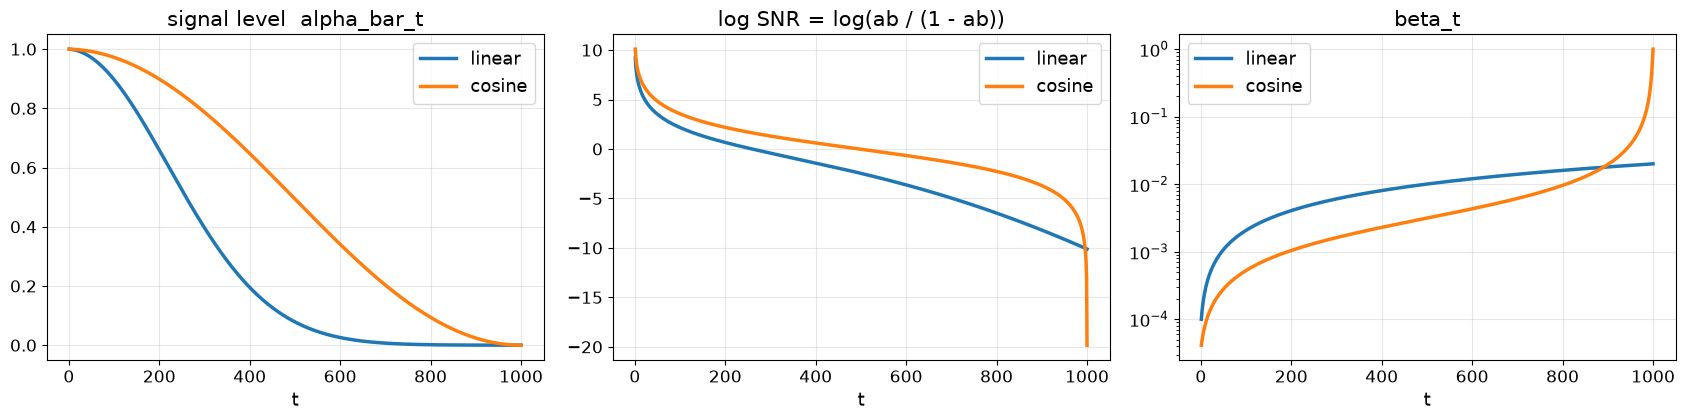

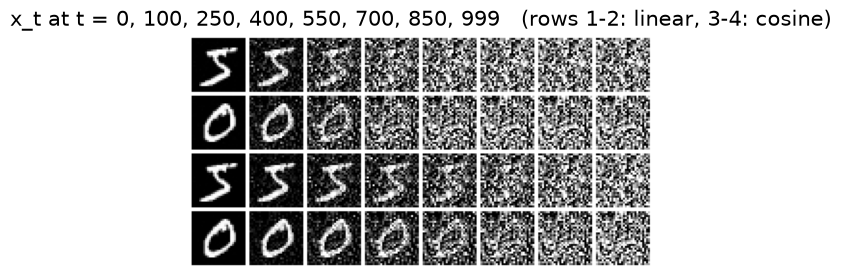

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
tt = np.arange(1, T + 1)
for s, c in zip(SCH.values(), ["tab:blue", "tab:orange"]):
    ax[0].plot(tt, s.ab.cpu(), c, lw=2.5, label=s.name)
    ax[1].plot(tt, s.logsnr.cpu(), c, lw=2.5, label=s.name)
    ax[2].plot(tt, s.betas.cpu(), c, lw=2.5, label=s.name)
ax[0].set_title("signal level  alpha_bar_t", fontsize=15); ax[1].set_title("log SNR = log(ab / (1 - ab))", fontsize=15)
ax[2].set_title("beta_t", fontsize=15); ax[2].set_yscale("log")
for a in ax: a.set_xlabel("t", fontsize=13); a.legend(fontsize=13); a.grid(alpha=0.3); a.tick_params(labelsize=12)
plt.tight_layout(); plt.show()

ts = [0, 100, 250, 400, 550, 700, 850, 999]
x0b = to_m1(Xtr[:3]).to(DEVICE); g = torch.Generator(device=DEVICE).manual_seed(0)
eps = torch.randn(x0b.shape, generator=g, device=DEVICE)
rows = []
for s in SCH.values():
    for k in range(2):
        rows += [s.q_sample(x0b[k:k + 1], torch.tensor([t], device=DEVICE), eps[k:k + 1])[0] for t in ts]
show(to_01(torch.stack(rows)), nrow=len(ts), title="x_t at t = " + ", ".join(map(str, ts)) + "   (rows 1-2: linear, 3-4: cosine)")

Что видно. Проверка замкнутой формы: после 10, 300 и 700 шагов цепи максимальное по 784 пикселям отклонение эмпирического среднего от $\sqrt{\bar\alpha_t}\,x_0$ равно 0,0013, 0,026 и 0,047, дисперсии от $1 - \bar\alpha_t$ — 0,0001, 0,017 и 0,056. Это шум оценки по 4000 копиям: при $t = 700$ стандартная ошибка среднего $\sqrt{0{,}8/4000} \approx 0{,}014$, а максимум по 784 пикселям составляет около 3,4 таких ошибок; для дисперсии $0{,}8\sqrt{2/4000} \approx 0{,}018$, максимум около 0,06. Систематического расхождения нет.

Расписания: у линейного $\bar\alpha_T = 4{,}0 \cdot 10^{-5}$, у косинусного $2{,}4 \cdot 10^{-9}$ (из-за ограничения $\beta_t \le 0{,}999$ на последних шагах, правый график). Половина сигнала по дисперсии теряется к шагу 259 у линейного и к шагу 496 у косинусного. У линейного треть всех шагов (33%) приходится на SNR < 0,01, то есть на почти чистый шум, у косинусного — 6%. На сетке изображений это видно напрямую: при линейном расписании цифра почти исчезает уже к $t = 400$, при косинусном она ещё различима при $t = 550$. Это и есть наблюдение Nichol и Dhariwal о «слишком шумном» конце линейного расписания ([Nichol & Dhariwal, 2021](https://proceedings.mlr.press/v139/nichol21a/nichol21a.pdf)).

## 14. Апостериорное распределение и веса ELBO

### 14.1. Две записи одного слагаемого

Слагаемое $L_{t-1}$ вариационной границы (раздел 4) при $\sigma_t^2 = \tilde\beta_t$ и $\epsilon$-параметризации равно

$
L_{t-1} = \frac{\beta_t^2}{2\sigma_t^2\,\alpha_t\,(1 - \bar\alpha_t)}\,\mathbb{E}\,\|\epsilon - \epsilon_\theta(x_t, t)\|^2 .
$

В терминах отношения сигнал/шум $\mathrm{SNR}(t) = \bar\alpha_t / (1 - \bar\alpha_t)$ тот же вес записывается как $\tfrac12\big(\mathrm{SNR}(t-1)/\mathrm{SNR}(t) - 1\big)$: граница целиком выражается через SNR ([Kingma et al., 2021](https://arxiv.org/abs/2107.00630)). Ниже проверяем, что формулы совпадают, и сравниваем эти веса с равномерным весом $L_{\text{simple}}$.

linear  max relative difference of two formulas: 6.4e-04   weight(t=2)/weight(t=T): 58.8   share of total ELBO weight in t=2..11: 0.19
cosine  max relative difference of two formulas: 5.6e-07   weight(t=2)/weight(t=T): 0.0   share of total ELBO weight in t=2..11: 0.00


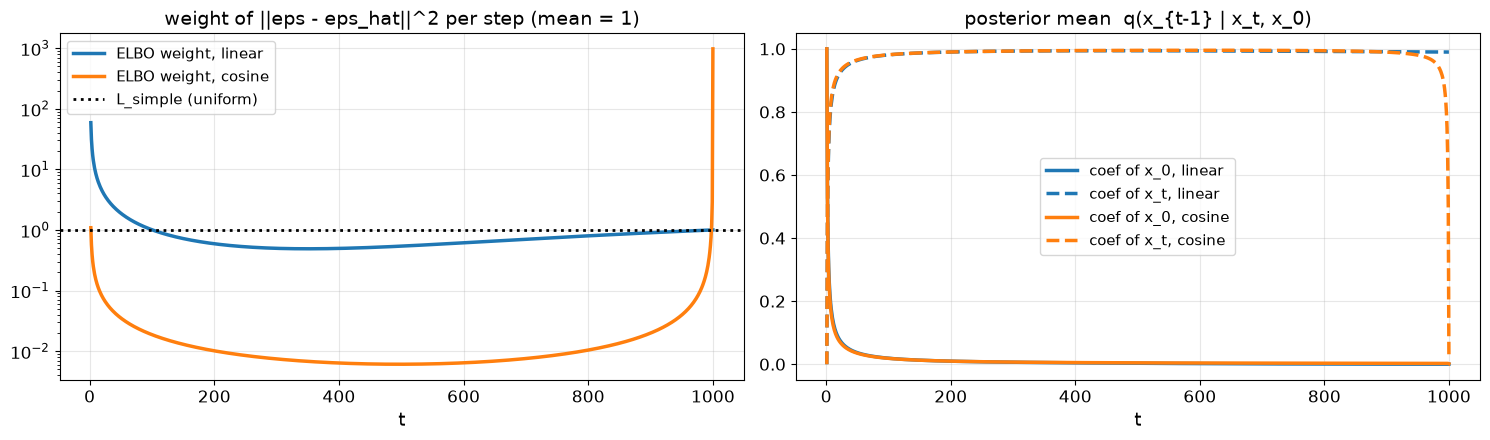

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for s, c in zip(SCH.values(), ["tab:blue", "tab:orange"]):
    b, a, ab, ab_prev, pv = [x.double().cpu()[1:] for x in (s.betas, s.alphas, s.ab, s.ab_prev, s.post_var)]
    w_ho = b ** 2 / (2 * pv * a * (1 - ab))
    snr, snr_prev = ab / (1 - ab), ab_prev / (1 - ab_prev)
    w_snr = 0.5 * (snr_prev / snr - 1)
    rel = (w_ho - w_snr).abs().max() / w_ho.abs().max()
    wn = w_ho / w_ho.mean()
    first = wn[:10].sum() / wn.sum()
    print(f"{s.name:7s} max relative difference of two formulas: {rel:.1e}   weight(t=2)/weight(t=T): {w_ho[0] / w_ho[-1]:.1f}"
          f"   share of total ELBO weight in t=2..11: {first:.2f}")
    ax[0].plot(np.arange(2, T + 1), wn, c, lw=2.5, label=f"ELBO weight, {s.name}")
    # апостериорное среднее: коэффициенты при x_0 и x_t
    ax[1].plot(np.arange(1, T + 1), s.post_c0.cpu(), c, lw=2.5, label=f"coef of x_0, {s.name}")
    ax[1].plot(np.arange(1, T + 1), s.post_ct.cpu(), c, lw=2.5, ls="--", label=f"coef of x_t, {s.name}")
ax[0].axhline(1, color="k", ls=":", lw=2, label="L_simple (uniform)")
ax[0].set_yscale("log"); ax[0].set_title("weight of ||eps - eps_hat||^2 per step (mean = 1)", fontsize=14)
ax[1].set_title("posterior mean  q(x_{t-1} | x_t, x_0)", fontsize=14)
for a_ in ax: a_.set_xlabel("t", fontsize=13); a_.legend(fontsize=11); a_.grid(alpha=0.3); a_.tick_params(labelsize=12)
plt.tight_layout(); plt.show()

Что видно. Две записи веса совпадают с точностью до округления: максимальное относительное расхождение 6,4·10⁻⁴ для линейного и 5,6·10⁻⁷ для косинусного расписания. Для линейного расписания вес при $t = 2$ в 58,8 раза больше, чем при $t = T$, и первые 10 шагов несут 19% суммарного веса границы. Равномерная $L_{\text{simple}}$ (пунктир) по сравнению с ней недооценивает малые $t$, как и описано в DDPM ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)). У косинусного расписания картина другая: вес огромен на последнем шаге (около $10^3$ от среднего), где $\beta_T = 0{,}999$, поэтому отношение «вес при $t = 2$ / вес при $t = T$» печатается как 0,0, а доля первых 10 шагов — как 0,00. Обучение прямо на ELBO с таким расписанием тратило бы почти весь градиент на один шаг; ещё один довод в пользу $L_{\text{simple}}$.

Правый график: почти на всех шагах апостериорное среднее — это $x_t$ с коэффициентом около 1 плюс малая добавка $x_0$. Коэффициент при $x_0$ становится большим только у $t \to 1$: последний шаг почти целиком «доверяет» оценке чистого изображения. У косинусного расписания в самом конце коэффициент при $x_t$ падает к нулю — следствие того же $\beta_T \approx 1$.

## 15. Двумерный пример: параметризации и score

### 15.1. Данные с известным score

Данные — смесь 8 гауссиан на окружности радиуса 1,5 со стандартным отклонением 0,1. Четыре моды «тяжёлые» (вес 0,2), четыре «лёгкие» (вес 0,05), так что на тяжёлые приходится 80% массы. Для смеси гауссиан зашумлённое распределение $p_t$ — снова смесь гауссиан со средними $\sqrt{\bar\alpha_t}\mu_k$ и дисперсией $\bar\alpha_t\sigma_0^2 + 1 - \bar\alpha_t$. Значит, точный score $\nabla_x \log p_t(x)$ и оптимальный предсказатель шума $\epsilon^*(x_t, t) = -\sqrt{1-\bar\alpha_t}\,\nabla \log p_t(x_t)$ известны в замкнутой форме. С ними и будем сравнивать обученные сети.

Здесь же определён общий сэмплер `sample`, который используется и для изображений. Он реализует DDIM с параметром $\eta$ ([Song et al., 2020](https://arxiv.org/abs/2010.02502)): при $\eta = 0$ шаг детерминированный (дискретизация probability flow ODE), при $\eta = 1$ и всех $T$ шагах — это анцестральный сэмплер DDPM с дисперсией $\tilde\beta_t$.

In [8]:
K_MODES, R, SIG0 = 8, 1.5, 0.1
ang = torch.arange(K_MODES) * 2 * math.pi / K_MODES
MU = torch.stack([R * ang.cos(), R * ang.sin()], 1).to(DEVICE)
PI = torch.tensor([0.2, 0.05] * 4, device=DEVICE)
HEAVY = torch.arange(K_MODES, device=DEVICE) % 2 == 0

def sample_data(n, gen=None):
    k = torch.multinomial(PI, n, replacement=True, generator=gen)
    return MU[k] + SIG0 * torch.randn(n, 2, device=DEVICE, generator=gen)

def true_eps(x, t, sch):
    """Точный E[eps | x_t] для смеси гауссиан: -sqrt(1 - ab) * score."""
    ab = sch.ab[t].view(-1, 1); var = ab * SIG0 ** 2 + 1 - ab
    d = x[:, None, :] - ab.sqrt()[:, None, :] * MU[None]                 # (B, K, 2)
    logw = PI.log()[None] - (d ** 2).sum(-1) / (2 * var)
    r = logw.softmax(-1)[..., None]
    score = -(r * d).sum(1) / var
    return -(1 - ab).sqrt() * score

def true_x0(x, t, sch):
    """Точный E[x_0 | x_t] для смеси гауссиан."""
    ab = sch.ab[t].view(-1, 1); var = ab * SIG0 ** 2 + 1 - ab
    d = x[:, None, :] - ab.sqrt()[:, None, :] * MU[None]
    r = (PI.log()[None] - (d ** 2).sum(-1) / (2 * var)).softmax(-1)[..., None]
    return (r * (MU[None] + (ab.sqrt() * SIG0 ** 2 / var)[:, None, :] * d)).sum(1)

def data_logpdf(x):
    d2 = ((x[:, None, :] - MU[None]) ** 2).sum(-1)
    return torch.logsumexp(PI.log()[None] - d2 / (2 * SIG0 ** 2), -1) - math.log(2 * math.pi * SIG0 ** 2)

def sample_quality(x):
    """Средний log p_data, доля в тяжёлых модах, доля точек вне мод (дальше 4 sigma0 от любого центра)."""
    d = ((x[:, None, :] - MU[None]) ** 2).sum(-1).sqrt(); near = d.argmin(1); off = d.min(1).values > 4 * SIG0
    return dict(logp=data_logpdf(x).clamp(min=-50).mean().item(),
                heavy=HEAVY[near[~off]].float().mean().item(), off=off.float().mean().item())

def timestep_embedding(t, dim, max_period=10000):
    """Синусоидальное кодирование номера шага, как позиционное кодирование в Transformer."""
    half = dim // 2
    freqs = torch.exp(-math.log(max_period) * torch.arange(half, device=t.device) / half)
    a = t.float()[:, None] * freqs[None]
    return torch.cat([a.cos(), a.sin()], -1)

def to_eps(out, x, t, sch, pred):
    """Перевод выхода сети (eps, x0 или v) в предсказание шума."""
    ab = sch.coef("ab", t, x.dim())
    if pred == "eps": return out
    if pred == "x0": return (x - ab.sqrt() * out) / (1 - ab).sqrt()
    if pred == "v": return (1 - ab).sqrt() * x + ab.sqrt() * out
    raise ValueError(pred)

def to_x0(out, x, t, sch, pred):
    ab = sch.coef("ab", t, x.dim())
    if pred == "eps": return (x - (1 - ab).sqrt() * out) / ab.sqrt()
    if pred == "x0": return out
    if pred == "v": return ab.sqrt() * x - (1 - ab).sqrt() * out
    raise ValueError(pred)

def target(x0, eps, t, sch, pred):
    ab = sch.coef("ab", t, x0.dim())
    return {"eps": eps, "x0": x0, "v": ab.sqrt() * eps - (1 - ab).sqrt() * x0}[pred]

@torch.no_grad()
def sample(eps_fn, shape, sch, steps=50, eta=0.0, clip=None, x_T=None, t_start=None, seed=0, traj=False):
    """DDIM(eta). eps_fn(x, t) -> eps. eta=0: детерминированный ODE-шаг; eta=1 и steps=T: DDPM."""
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    t_start = sch.T - 1 if t_start is None else t_start
    ts = np.unique(np.linspace(t_start, 0, steps).round().astype(int))[::-1]
    x = torch.randn(shape, generator=g, device=DEVICE) if x_T is None else x_T.clone()
    path = [x.cpu()]
    for i, t in enumerate(ts):
        tb = torch.full((shape[0],), int(t), device=DEVICE, dtype=torch.long)
        ab = sch.ab[t]; ab_prev = sch.ab[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0, device=DEVICE)
        with torch.enable_grad() if getattr(eps_fn, "needs_grad", False) else torch.no_grad():
            eps = eps_fn(x, tb)
        x0 = (x - (1 - ab).sqrt() * eps) / ab.sqrt()
        if clip is not None:
            x0 = x0.clamp(-clip, clip); eps = (x - ab.sqrt() * x0) / (1 - ab).sqrt()
        sigma = eta * ((1 - ab_prev) / (1 - ab) * (1 - ab / ab_prev)).clamp(min=0).sqrt()
        x = ab_prev.sqrt() * x0 + (1 - ab_prev - sigma ** 2).clamp(min=0).sqrt() * eps
        if eta > 0 and i + 1 < len(ts): x = x + sigma * torch.randn(shape, generator=g, device=DEVICE)
        if traj: path.append(x.cpu())
    return (x, torch.stack(path)) if traj else x

### 15.2. Три параметризации

Обучаем три одинаковые MLP (3 скрытых слоя по 256, синусоидальное кодирование $t$) с косинусным расписанием. Отличается только цель: шум $\epsilon$, чистые данные $x_0$ или скорость $v = \sqrt{\bar\alpha_t}\,\epsilon - \sqrt{1-\bar\alpha_t}\,x_0$ ([Salimans & Ho, 2022](https://arxiv.org/abs/2202.00512)). Потеря у каждой — MSE в своём пространстве с равным весом по $t$. Затем выход каждой сети переводим в $\epsilon$ и в $x_0$ и сравниваем с точными условными средними $\mathbb{E}[\epsilon \mid x_t]$ и $\mathbb{E}[x_0 \mid x_t]$ по уровням шума: именно к ним сходится минимизатор MSE.

In [9]:
class MLP2D(nn.Module):
    def __init__(self, pred, h=256, temb=64):
        super().__init__(); self.pred, self.temb = pred, temb
        self.net = nn.Sequential(nn.Linear(2 + temb, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(),
                                 nn.Linear(h, h), nn.SiLU(), nn.Linear(h, 2))
    def forward(self, x, t): return self.net(torch.cat([x, timestep_embedding(t, self.temb)], -1))

def train_2d(pred, sch, steps, bs=1024, seed=0):
    seed_all(seed); m = MLP2D(pred).to(DEVICE); opt = torch.optim.Adam(m.parameters(), 2e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps); losses = []
    for i in range(steps):
        x0 = sample_data(bs); t = torch.randint(0, sch.T, (bs,), device=DEVICE); eps = torch.randn_like(x0)
        loss = F.mse_loss(m(sch.q_sample(x0, t, eps), t), target(x0, eps, t, sch, pred))
        opt.zero_grad(); loss.backward(); opt.step(); sched.step(); losses.append(loss.item())
    return m.eval(), losses

sch = SCH["cosine"]; TOY = {}
for pred in ["eps", "x0", "v"]:
    with Timer() as tm: TOY[pred], _ = train_2d(pred, sch, S["steps_2d"])
    print(f"{pred:3s}: {tm.s:.0f} s")

@torch.no_grad()
def errors_by_t(m, sch, n=4000, buckets=10):
    rows = []
    g = torch.Generator(device=DEVICE).manual_seed(5)
    for b in range(buckets):
        t = torch.randint(b * sch.T // buckets, (b + 1) * sch.T // buckets, (n,), device=DEVICE, generator=g)
        x0 = sample_data(n, g); x = sch.q_sample(x0, t, torch.randn(n, 2, device=DEVICE, generator=g))
        out = m(x, t)
        e_hat, x0_hat = to_eps(out, x, t, sch, m.pred), to_x0(out, x, t, sch, m.pred)
        e_star, x0_star = true_eps(x, t, sch), true_x0(x, t, sch)
        rows.append(((e_hat - e_star).pow(2).sum(1).mean().item(), (x0_hat - x0_star).pow(2).sum(1).mean().item()))
    return np.array(rows)

ERR = {p: errors_by_t(m, sch) for p, m in TOY.items()}
print("bucket (t range)        " + "   ".join(f"{p:>16s}" for p in ERR))
print("                        " + "   ".join(f"{'eps-err  x0-err':>16s}" for p in ERR))
for b in range(10):
    print(f"t in [{b * 100:3d}, {(b + 1) * 100:4d})        " + "   ".join(f"{ERR[p][b, 0]:7.4f} {ERR[p][b, 1]:8.4f}" for p in ERR))

eps: 15 s


x0 : 15 s


v  : 15 s


bucket (t range)                     eps                 x0                  v
                         eps-err  x0-err    eps-err  x0-err    eps-err  x0-err
t in [  0,  100)         0.0353   0.0005    3.1743   0.0052    0.0153   0.0002
t in [100,  200)         0.0351   0.0019    0.3099   0.0180    0.0167   0.0009
t in [200,  300)         0.0076   0.0013    0.0529   0.0084    0.0059   0.0010
t in [300,  400)         0.0035   0.0014    0.0051   0.0019    0.0025   0.0009
t in [400,  500)         0.0022   0.0016    0.0014   0.0011    0.0012   0.0009
t in [500,  600)         0.0009   0.0013    0.0006   0.0009    0.0005   0.0007
t in [600,  700)         0.0007   0.0020    0.0003   0.0007    0.0002   0.0005
t in [700,  800)         0.0009   0.0055    0.0001   0.0006    0.0001   0.0006
t in [800,  900)         0.0014   0.0262    0.0000   0.0007    0.0000   0.0006
t in [900, 1000)         0.0012 7226.5527    0.0000   0.0007    0.0000   0.0004


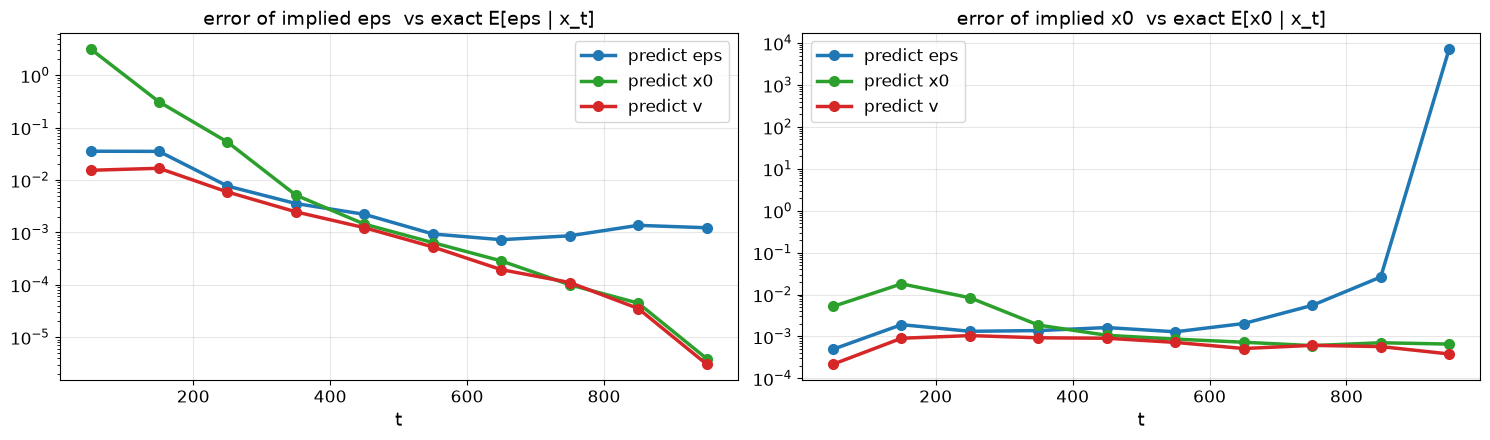

model      sampler           mean log p_data  heavy share  off-mode
data       -                          -0.121        0.794     0.001


predict eps DDPM, 1000 steps           -0.367        0.815     0.018


predict eps DDIM, 50 steps            -39.750        0.925     0.963
predict eps DDIM, 10 steps            -49.857        0.667     0.999


predict x0 DDPM, 1000 steps           -0.084        0.966     0.046


predict x0 DDIM, 50 steps             -1.531        0.919     0.109
predict x0 DDIM, 10 steps             -2.481        0.878     0.162


predict v  DDPM, 1000 steps           -0.156        0.810     0.007


predict v  DDIM, 50 steps             -0.352        0.800     0.026
predict v  DDIM, 10 steps             -0.782        0.779     0.070


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
mid = np.arange(50, 1000, 100)
for p, c in zip(ERR, ["tab:blue", "tab:green", "tab:red"]):
    ax[0].plot(mid, ERR[p][:, 0], "o-", color=c, lw=2.5, ms=7, label=f"predict {p}")
    ax[1].plot(mid, ERR[p][:, 1], "o-", color=c, lw=2.5, ms=7, label=f"predict {p}")
ax[0].set_title("error of implied eps  vs exact E[eps | x_t]", fontsize=14)
ax[1].set_title("error of implied x0  vs exact E[x0 | x_t]", fontsize=14)
for a in ax: a.set_yscale("log"); a.set_xlabel("t", fontsize=13); a.legend(fontsize=12); a.grid(alpha=0.3); a.tick_params(labelsize=12)
plt.tight_layout(); plt.show()

print(f"{'model':10s} {'sampler':16s} {'mean log p_data':>16s} {'heavy share':>12s} {'off-mode':>9s}")
q = sample_quality(sample_data(4000, torch.Generator(device=DEVICE).manual_seed(9)))
print(f"{'data':10s} {'-':16s} {q['logp']:16.3f} {q['heavy']:12.3f} {q['off']:9.3f}")
TOY_Q = {}
for p, m in TOY.items():
    fn = lambda x, t, m=m: to_eps(m(x, t), x, t, sch, m.pred)
    for name, kw in [("DDPM, 1000 steps", dict(steps=1000, eta=1.0)), ("DDIM, 50 steps", dict(steps=50, eta=0.0)),
                     ("DDIM, 10 steps", dict(steps=10, eta=0.0))]:
        qq = sample_quality(sample(fn, (4000, 2), sch, **kw)); TOY_Q[(p, name)] = qq
        print(f"{'predict ' + p:10s} {name:16s} {qq['logp']:16.3f} {qq['heavy']:12.3f} {qq['off']:9.3f}")

Что видно. Таблица ошибок подтверждает разбор из раздела 5. У $\epsilon$-модели ошибка шума мала везде (не больше 0,035), но пересчёт в $\hat x_0$ при $t \ge 900$ даёт ошибку 7227: множитель $\sqrt{1-\bar\alpha_t}/\sqrt{\bar\alpha_t}$ на последнем шаге косинусного расписания равен $2 \cdot 10^4$. У $x_0$-модели всё наоборот: $\hat x_0$ хорош при больших $t$, но ошибка шума при $t < 100$ равна 3,17. У $v$-модели обе ошибки малы на всех уровнях: не больше 0,017 по $\epsilon$ и 0,001 по $x_0$.

Сэмплеры. У данных средний $\log p$ равен −0,121, доля тяжёлых мод 0,794. $\epsilon$-модель с DDPM на 1000 шагах работает (−0,367; 0,815; 1,8% точек вне мод), но с DDIM ломается: 96% точек на 50 шагах и почти 100% на 10 шагах оказываются вне мод. Причина — первый шаг из $t = 999$: огромная ошибка $\hat x_0$ переносится в детерминированную траекторию и не исправляется, а DDPM на каждом шаге добавляет свежий шум, и следующие шаги её «забывают». $x_0$-модель даёт DDPM с правдоподобием даже выше данных (−0,084), но за счёт перекоса: доля тяжёлых мод 0,966 вместо 0,794, а на DDIM 11–16% точек уходят из мод. $v$-модель ближе всех к данным при любом сэмплере: доля тяжёлых мод 0,810 / 0,800 / 0,779 и 0,7% / 2,6% / 7% точек вне мод для DDPM 1000, DDIM 50 и DDIM 10. Поэтому U-Net и DiT ниже обучаются на $v$-цель, что согласуется с рекомендациями для расписаний с почти нулевым конечным SNR ([Lin et al., 2024](https://arxiv.org/abs/2305.08891)).

## 16. Двумерный пример: score, SDE, ODE и Langevin

### 16.1. Выученное и точное поле score

Score-модель и $\epsilon$-модель — одно и то же с точностью до множителя: $s_\theta(x_t, t) = -\epsilon_\theta(x_t, t)/\sqrt{1-\bar\alpha_t}$ (раздел 6). Рисуем поле score для трёх уровней шума: при большом шуме оно почти радиальное и указывает к центру, при малом — разбивается на 8 «воронок» вокруг мод.

t= 30: mean cosine(learned, exact) = 0.959, median relative error = 0.331
t=300: mean cosine(learned, exact) = 0.990, median relative error = 0.045
t=800: mean cosine(learned, exact) = 0.997, median relative error = 0.022


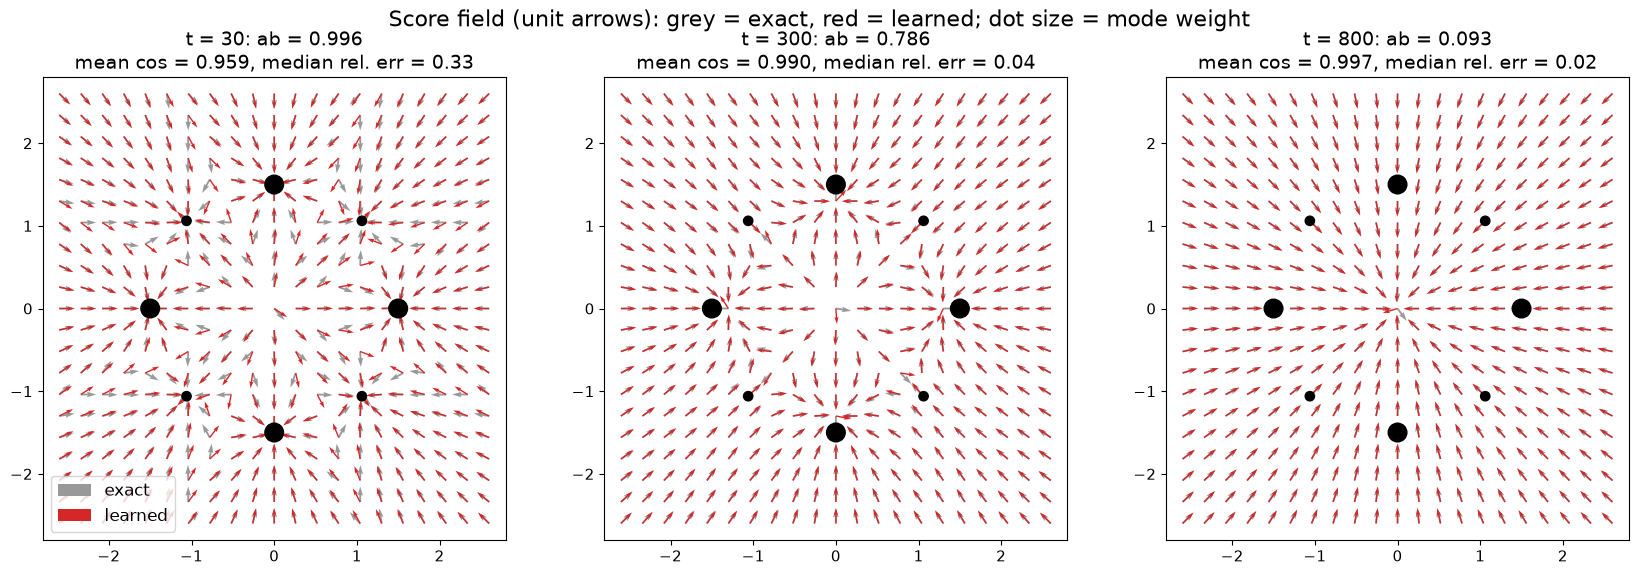

In [11]:
m_eps = TOY["eps"]
def model_score(x, t): return -m_eps(x, t) / (1 - sch.coef("ab", t, 2)).sqrt()
def exact_score(x, t): return -true_eps(x, t, sch) / (1 - sch.coef("ab", t, 2)).sqrt()

gx = torch.linspace(-2.6, 2.6, 21, device=DEVICE)
grid = torch.stack(torch.meshgrid(gx, gx, indexing="xy"), -1).reshape(-1, 2)
fig, ax = plt.subplots(1, 3, figsize=(17, 5.6))
with torch.no_grad():
    for a, tv in zip(ax, [30, 300, 800]):
        t = torch.full((len(grid),), tv, device=DEVICE)
        sm, se = model_score(grid, t), exact_score(grid, t)
        cos = F.cosine_similarity(sm, se, dim=1).mean().item()
        rel = ((sm - se).norm(dim=1) / se.norm(dim=1).clamp_min(1e-6)).median().item()
        n_m, n_e = sm / sm.norm(dim=1, keepdim=True), se / se.norm(dim=1, keepdim=True)
        G = grid.cpu()
        a.quiver(G[:, 0], G[:, 1], n_e[:, 0].cpu(), n_e[:, 1].cpu(), color="0.6", scale=30, width=0.004, label="exact")
        a.quiver(G[:, 0], G[:, 1], n_m[:, 0].cpu(), n_m[:, 1].cpu(), color="tab:red", scale=30, width=0.003, label="learned")
        a.scatter(MU[:, 0].cpu(), MU[:, 1].cpu(), s=(PI * 900).cpu(), c="k", zorder=3)
        a.set_title(f"t = {tv}: ab = {sch.ab[tv].item():.3f}\nmean cos = {cos:.3f}, median rel. err = {rel:.2f}", fontsize=14)
        a.set_aspect("equal"); a.set_xlim(-2.8, 2.8); a.set_ylim(-2.8, 2.8); a.tick_params(labelsize=11)
        print(f"t={tv:3d}: mean cosine(learned, exact) = {cos:.3f}, median relative error = {rel:.3f}")
ax[0].legend(fontsize=12, loc="lower left")
plt.suptitle("Score field (unit arrows): grey = exact, red = learned; dot size = mode weight", fontsize=16)
plt.tight_layout(); plt.show()

### 16.2. Стохастические и детерминированные траектории

Обратная SDE и probability flow ODE имеют одинаковые маргинальные распределения $p_t$ ([Song et al., 2021](https://arxiv.org/abs/2011.13456)), но разные траектории. Используем $v$-модель из раздела 15 (у $\epsilon$-модели DDIM ломается, см. таблицу там). Из одних и тех же стартовых точек запускаем DDPM (1000 стохастических шагов) и DDIM с $\eta = 0$ (50 детерминированных шагов). Затем проверяем детерминированность: два запуска DDIM с разными зёрнами из одного $x_T$ должны совпасть, два запуска DDPM — нет.

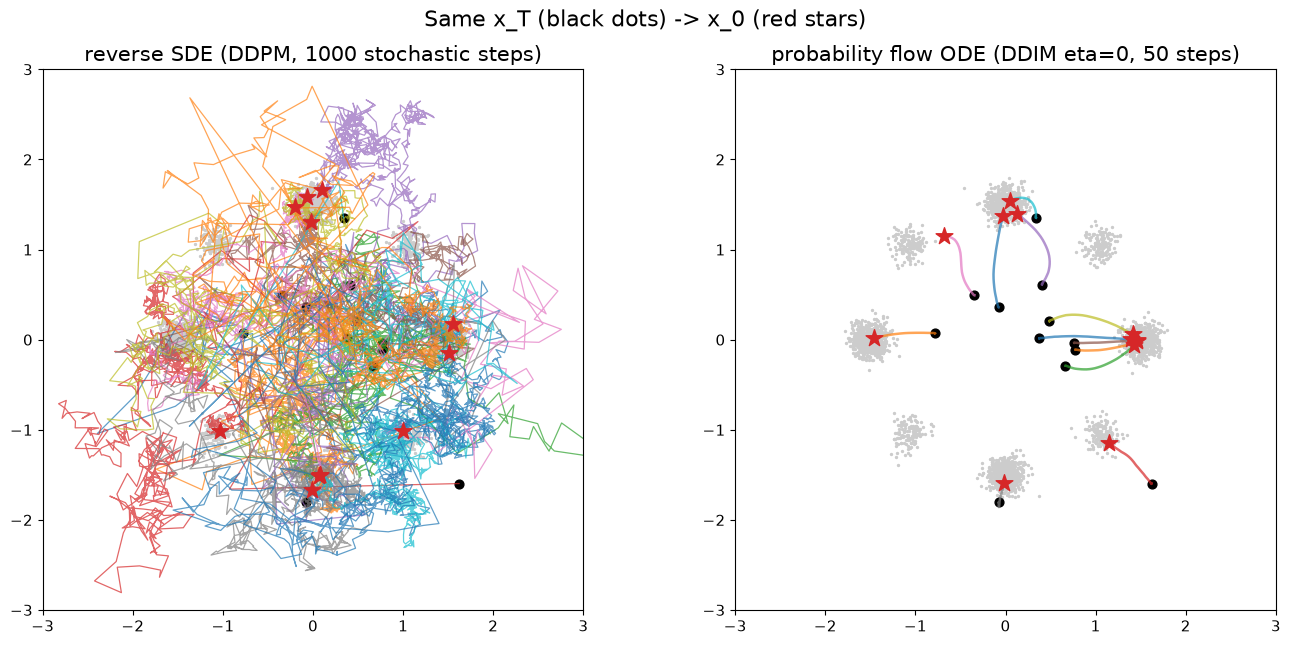

DDIM eta=0, two seeds, same x_T: max |difference| = 0.00e+00
DDPM,       two seeds, same x_T: mean |difference| = 2.363


In [12]:
fn_v = lambda x, t: to_eps(TOY["v"](x, t), x, t, sch, "v")
x_T = torch.randn(12, 2, generator=torch.Generator(device=DEVICE).manual_seed(3), device=DEVICE)
_, P_sde = sample(fn_v, (12, 2), sch, steps=1000, eta=1.0, x_T=x_T, traj=True, seed=1)
_, P_ode = sample(fn_v, (12, 2), sch, steps=50, eta=0.0, x_T=x_T, traj=True, seed=1)
bg = sample_data(3000, torch.Generator(device=DEVICE).manual_seed(4)).cpu()
fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
for a, P, title in [(ax[0], P_sde, "reverse SDE (DDPM, 1000 stochastic steps)"), (ax[1], P_ode, "probability flow ODE (DDIM eta=0, 50 steps)")]:
    a.scatter(bg[:, 0], bg[:, 1], s=2, c="0.8")
    for j in range(12):
        a.plot(P[:, j, 0], P[:, j, 1], lw=0.9 if P.shape[0] > 100 else 1.8, alpha=0.7)
        a.scatter(P[0, j, 0], P[0, j, 1], marker="o", s=40, c="k"); a.scatter(P[-1, j, 0], P[-1, j, 1], marker="*", s=160, c="tab:red", zorder=3)
    a.set_title(title, fontsize=15); a.set_aspect("equal"); a.set_xlim(-3, 3); a.set_ylim(-3, 3); a.tick_params(labelsize=11)
plt.suptitle("Same x_T (black dots) -> x_0 (red stars)", fontsize=16); plt.tight_layout(); plt.show()

a1 = sample(fn_v, (12, 2), sch, steps=50, eta=0.0, x_T=x_T, seed=1); a2 = sample(fn_v, (12, 2), sch, steps=50, eta=0.0, x_T=x_T, seed=2)
b1 = sample(fn_v, (12, 2), sch, steps=1000, eta=1.0, x_T=x_T, seed=1); b2 = sample(fn_v, (12, 2), sch, steps=1000, eta=1.0, x_T=x_T, seed=2)
print(f"DDIM eta=0, two seeds, same x_T: max |difference| = {(a1 - a2).abs().max().item():.2e}")
print(f"DDPM,       two seeds, same x_T: mean |difference| = {(b1 - b2).norm(dim=1).mean().item():.3f}")

### 16.3. Langevin на одном уровне шума и с отжигом

Score-подход к сэмплингу — динамика Ланжевена $x \leftarrow x + \tfrac{\delta}{2}\nabla \log p(x) + \sqrt{\delta}\,z$. Если использовать только score почти чистых данных ($t = 5$), цепочка быстро находит ближайшую моду, но почти не переходит между модами: веса мод определяются стартовой точкой, а не данными. Annealed Langevin ([Song & Ermon, 2019](https://arxiv.org/abs/1907.05600)) начинает с большого шума, где моды «слиты», и постепенно уменьшает его. Стартуем 4000 цепочек из равномерного распределения на квадрате $[-2{,}5;\,2{,}5]^2$, шаг $\delta = 0{,}1\cdot\mathrm{Var}_t$, где $\mathrm{Var}_t = \bar\alpha_t\sigma_0^2 + 1 - \bar\alpha_t$.

data                                     heavy-mode share=0.794  off-mode=0.001  mean log p=-0.121
Langevin at t=5 only, 1000 steps         heavy-mode share=0.727  off-mode=0.003  mean log p=0.040
annealed Langevin, 20 levels x 50 steps  heavy-mode share=0.856  off-mode=0.002  mean log p=0.250


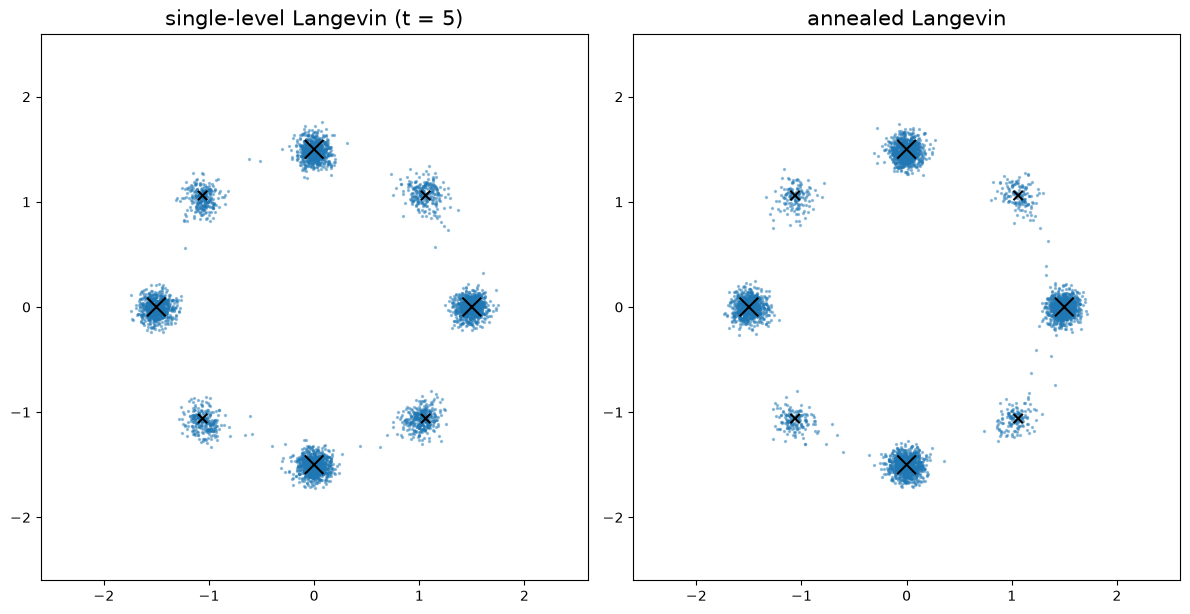

In [13]:
@torch.no_grad()
def langevin(levels, n_steps, n=4000, seed=0):
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    x = (torch.rand(n, 2, generator=g, device=DEVICE) * 5 - 2.5)
    prev = levels[0]
    for tv in levels:
        ab = sch.ab[tv]; var = ab * SIG0 ** 2 + 1 - ab; delta = 0.1 * var
        x = x * (ab / sch.ab[prev]).sqrt(); prev = tv                 # переход к масштабу следующего уровня
        t = torch.full((n,), tv, device=DEVICE)
        for _ in range(n_steps):
            x = x + 0.5 * delta * model_score(x, t) + delta.sqrt() * torch.randn(x.shape, generator=g, device=DEVICE)
    return x / sch.ab[levels[-1]].sqrt()

single = langevin([5], 1000)
annealed = langevin([int(v) for v in np.linspace(700, 5, 20).round()], 50)
for name, x in [("data", sample_data(4000, torch.Generator(device=DEVICE).manual_seed(9))),
                ("Langevin at t=5 only, 1000 steps", single), ("annealed Langevin, 20 levels x 50 steps", annealed)]:
    q = sample_quality(x); print(f"{name:40s} heavy-mode share={q['heavy']:.3f}  off-mode={q['off']:.3f}  mean log p={q['logp']:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a, x, title in [(ax[0], single, "single-level Langevin (t = 5)"), (ax[1], annealed, "annealed Langevin")]:
    x = x.cpu(); a.scatter(x[:, 0], x[:, 1], s=2, alpha=0.4)
    a.scatter(MU[:, 0].cpu(), MU[:, 1].cpu(), s=(PI * 900).cpu(), c="k", marker="x")
    a.set_title(title, fontsize=15); a.set_aspect("equal"); a.set_xlim(-2.6, 2.6); a.set_ylim(-2.6, 2.6)
plt.tight_layout(); plt.show()

Что видно. Выученное поле score (из $\epsilon$-модели) хорошо совпадает с точным при большом и среднем шуме: средний косинус 0,997 при $t = 800$ и 0,990 при $t = 300$, медианная относительная ошибка 2,2% и 4,5%. При $t = 30$ косинус падает до 0,959, а относительная ошибка растёт до 33%: поле становится резким, расходящиеся серые и красные стрелки видны в промежутках между модами, где данных почти нет. Это та самая трудность одноуровневого score matching, о которой писали Song и Ermon ([Song & Ermon, 2019](https://arxiv.org/abs/1907.05600)).

Траектории: DDPM блуждает и приходит в моды извилистыми путями, DDIM идёт по гладким кривым к ближайшей «своей» моде. Проверка детерминированности: два запуска DDIM из одного $x_T$ с разными зёрнами совпадают точно (расхождение 0), у DDPM конечные точки в среднем отстоят на 2,36 — это порядка расстояния между соседними модами, то есть они попадают в разные моды.

Ланжевен: обе версии почти не дают точек вне мод (0,3% и 0,2%). Одноуровневая цепочка при $t = 5$ недооценивает тяжёлые моды (0,727 против 0,794 у данных): доля моды определяется в основном тем, сколько стартовых точек попало в её «воронку». Отжиг меняет картину, но в этом запуске перекос получился в другую сторону — 0,856. При 50 шагах на уровень и шаге $\delta = 0{,}1\,\mathrm{Var}_t$ цепочки на крупных уровнях шума не успевают прийти в равновесие; средний $\log p$ у обеих выше, чем у данных (0,04 и 0,25 против −0,121), то есть точки сжаты к центрам мод сильнее, чем в данных. Отжиг решает проблему перехода между модами, но точные веса требуют больше шагов или корректора (см. задание 4).

## 17. U-Net с timestep embedding

### 17.1. Кодирование времени

Номер шага $t$ подаётся в сеть так же, как позиция в Transformer: вектор синусов и косинусов с геометрически убывающими частотами ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)), затем двухслойный MLP. Низкие частоты различают «рано» и «поздно», высокие — соседние шаги.

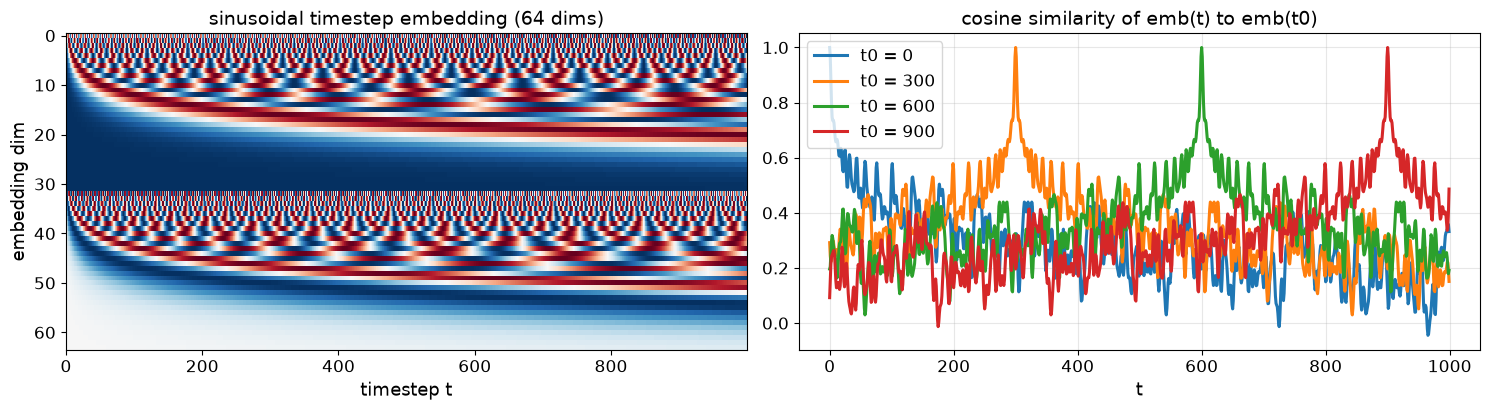

In [14]:
emb = timestep_embedding(torch.arange(T), 64).cpu()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
ax[0].imshow(emb.T, aspect="auto", cmap="RdBu", interpolation="nearest")
ax[0].set_xlabel("timestep t", fontsize=13); ax[0].set_ylabel("embedding dim", fontsize=13)
ax[0].set_title("sinusoidal timestep embedding (64 dims)", fontsize=14)
sim = F.cosine_similarity(emb[:, None], emb[None, ::100], dim=-1)
for j, t0 in enumerate(range(0, T, 100)):
    if t0 in (0, 300, 600, 900): ax[1].plot(sim[:, j], lw=2.2, label=f"t0 = {t0}")
ax[1].set_xlabel("t", fontsize=13); ax[1].set_title("cosine similarity of emb(t) to emb(t0)", fontsize=14)
ax[1].legend(fontsize=12); ax[1].grid(alpha=0.3)
for a in ax: a.tick_params(labelsize=12)
plt.tight_layout(); plt.show()

### 17.2. Архитектура

Маленькая версия U-Net из DDPM и ADM ([Ho et al., 2020](https://arxiv.org/abs/2006.11239); [Dhariwal & Nichol, 2021](https://arxiv.org/abs/2105.05233)):

- три уровня разрешения 28 → 14 → 7; на CPU каналы $c, 2c, 4c$ при $c = 16$ и один остаточный блок на уровень, на GPU $c, 2c, 2c$ при $c = 64$ и два блока (на CPU сеть урезана ради времени: свёртки на полном разрешении — главная статья затрат);
- в каждом остаточном блоке GroupNorm, SiLU, свёртки 3×3; условие (время плюс класс) входит через AdaGN: $h \leftarrow \mathrm{GroupNorm}(h)\,(1 + \gamma) + \beta$, где $\gamma, \beta$ — линейная функция эмбеддинга;
- self-attention на разрешении 7×7 и в середине сети;
- skip-соединения конкатенацией между энкодером и декодером, как в исходной U-Net ([Ronneberger et al., 2015](https://arxiv.org/abs/1505.04597));
- класс кодируется эмбеддингом с 11 строками: цифры 0–9 и «пустой» класс 10 для classifier-free guidance;
- последний слой инициализирован нулями: в начале обучения выход сети равен нулю.

In [15]:
NULL = 10

class ResBlock(nn.Module):
    def __init__(self, cin, cout, edim, drop=0.0):
        super().__init__()
        self.n1, self.c1 = nn.GroupNorm(8, cin), nn.Conv2d(cin, cout, 3, padding=1)
        self.emb = nn.Linear(edim, 2 * cout)
        self.n2, self.c2 = nn.GroupNorm(8, cout), nn.Conv2d(cout, cout, 3, padding=1)
        self.drop = nn.Dropout(drop); self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x, e):
        h = self.c1(F.silu(self.n1(x)))
        g, b = self.emb(F.silu(e))[:, :, None, None].chunk(2, 1)
        h = self.n2(h) * (1 + g) + b                                     # AdaGN: условие масштабирует и сдвигает признаки
        return self.skip(x) + self.c2(self.drop(F.silu(h)))

class Attn(nn.Module):
    def __init__(self, c, heads=4):
        super().__init__(); self.n, self.h = nn.GroupNorm(8, c), heads
        self.qkv, self.out = nn.Conv2d(c, 3 * c, 1), nn.Conv2d(c, c, 1)
    def forward(self, x, e=None):
        B, C, H, W = x.shape
        q, k, v = self.qkv(self.n(x)).reshape(B, 3, self.h, C // self.h, H * W).transpose(-1, -2).unbind(1)
        o = F.scaled_dot_product_attention(q, k, v).transpose(-1, -2).reshape(B, C, H, W)
        return x + self.out(o)

class UNet(nn.Module):
    def __init__(self, ch=32, mult=(1, 2, 2), n_res=2, attn_res=(7,), n_cls=11, drop=0.1):
        super().__init__(); edim = 4 * ch; self.ch = ch
        self.t_mlp = nn.Sequential(nn.Linear(ch, edim), nn.SiLU(), nn.Linear(edim, edim))
        self.cls = nn.Embedding(n_cls, edim)
        self.inp = nn.Conv2d(1, ch, 3, padding=1)
        self.down, chans, c, res = nn.ModuleList(), [ch], ch, 28
        for i, m in enumerate(mult):
            for _ in range(n_res):
                blk = nn.ModuleList([ResBlock(c, ch * m, edim, drop)]); c = ch * m
                if res in attn_res: blk.append(Attn(c))
                self.down.append(blk); chans.append(c)
            if i < len(mult) - 1:
                self.down.append(nn.ModuleList([nn.Conv2d(c, c, 3, stride=2, padding=1)])); chans.append(c); res //= 2
        self.mid = nn.ModuleList([ResBlock(c, c, edim, drop), Attn(c), ResBlock(c, c, edim, drop)])
        self.up = nn.ModuleList()
        for i, m in reversed(list(enumerate(mult))):
            for _ in range(n_res + 1):
                blk = nn.ModuleList([ResBlock(c + chans.pop(), ch * m, edim, drop)]); c = ch * m
                if res in attn_res: blk.append(Attn(c))
                self.up.append(blk)
            if i > 0: self.up.append(nn.ModuleList([nn.Upsample(scale_factor=2, mode="nearest"), nn.Conv2d(c, c, 3, padding=1)])); res *= 2
        self.out = nn.Sequential(nn.GroupNorm(8, c), nn.SiLU(), nn.Conv2d(c, 1, 3, padding=1))
        nn.init.zeros_(self.out[-1].weight); nn.init.zeros_(self.out[-1].bias)

    def forward(self, x, t, y):
        e = self.t_mlp(timestep_embedding(t, self.ch)) + self.cls(y)
        h = self.inp(x); hs = [h]
        for blk in self.down:
            if isinstance(blk[0], ResBlock):
                h = blk[0](h, e)
                if len(blk) > 1: h = blk[1](h)
            else: h = blk[0](h)
            hs.append(h)
        h = self.mid[2](self.mid[1](self.mid[0](h, e)), e)
        for blk in self.up:
            if isinstance(blk[0], ResBlock):
                h = blk[0](torch.cat([h, hs.pop()], 1), e)
                if len(blk) > 1: h = blk[1](h)
            else: h = blk[1](blk[0](h))
        return self.out(h)

n_params = lambda m: sum(p.numel() for p in m.parameters())
UNET_KW = dict(ch=S["ch"], mult=S["mult"], n_res=S["n_res"], drop=S["drop"])
seed_all(0); unet = UNet(**UNET_KW).to(DEVICE)
xb = to_m1(Xtr[:S["bs"]]).to(DEVICE); tb = torch.randint(0, T, (S["bs"],), device=DEVICE); yb = Ytr[:S["bs"]].to(DEVICE)
with torch.no_grad(): out = unet(xb, tb, yb)
print(f"U-Net: {n_params(unet) / 1e6:.2f}M params, input {tuple(xb.shape)} -> output {tuple(out.shape)}, |output| at init = {out.abs().max().item():.1f}")
opt_tmp = torch.optim.Adam(unet.parameters(), 1e-4)
with Timer() as tm:
    for _ in range(5):
        loss = F.mse_loss(unet(xb, tb, yb), torch.randn_like(xb)); opt_tmp.zero_grad(); loss.backward(); opt_tmp.step()
print(f"one training step at batch {S['bs']}: {tm.s / 5:.3f} s")
with torch.no_grad(), Timer() as tm: unet(xb.repeat(4, 1, 1, 1)[:200], tb.repeat(4)[:200], yb.repeat(4)[:200])
print(f"one forward pass at batch 200: {tm.s:.3f} s")

U-Net: 0.72M params, input (64, 1, 28, 28) -> output (64, 1, 28, 28), |output| at init = 0.0


one training step at batch 64: 0.338 s


one forward pass at batch 200: 0.333 s


Что видно. На тепловой карте верхние строки каждой половины (высокие частоты) быстро осциллируют по $t$, нижние (низкие частоты) меняются медленно на всём диапазоне: самый медленный период — около $4{,}7 \cdot 10^4$ шагов, больше $T$. Косинусное сходство $\mathrm{emb}(t)$ с $\mathrm{emb}(t_0)$ равно 1 в точке $t_0$, быстро падает у соседей и дальше колеблется на уровне 0,2–0,5: кодирование различает и близкие, и далёкие шаги, но не монотонно по расстоянию, поэтому за ним стоит обучаемый MLP.

U-Net в CPU-режиме имеет 0,72 млн параметров, выход при инициализации ровно нулевой (нулевой последний слой). Шаг обучения на батче 64 занимает 0,34 с, прямой проход на батче 200 — 0,33 с; значит, 1000 шагов DDPM на 200 изображений займут около 5,5 минуты, что и определяет размеры экспериментов ниже.

## 18. Обучение DDPM на MNIST

### 18.1. Цикл обучения

Алгоритм обучения DDPM ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)) умещается в несколько строк: взять $x_0$, равномерно выбрать $t$, сгенерировать $\epsilon$, построить $x_t$ по замкнутой формуле и минимизировать MSE между выходом сети и целью. В качестве цели здесь выбрана скорость $v = \sqrt{\bar\alpha_t}\,\epsilon - \sqrt{1-\bar\alpha_t}\,x_0$, а не шум $\epsilon$, как в исходной DDPM. Причина видна в разделе 15: при косинусном расписании $\bar\alpha_T \approx 2{,}4 \cdot 10^{-9}$, и на первых шагах сэмплера ошибка $\epsilon$-модели в пересчёте на $\hat x_0$ умножается на $1/\sqrt{\bar\alpha_t}$ (до $2 \cdot 10^4$); детерминированный DDIM эту ошибку не «забывает». Для $v$-цели коэффициенты перевода не больше 1 ([Salimans & Ho, 2022](https://arxiv.org/abs/2202.00512)); тот же рецепт рекомендуют для расписаний с почти нулевым конечным SNR ([Lin et al., 2024](https://arxiv.org/abs/2305.08891)). Сэмплеры при этом по-прежнему работают с $\hat\epsilon$, полученным из $\hat v$ функцией `to_eps`. Два добавления:

- с вероятностью $p_{\text{uncond}} = 0{,}1$ класс заменяется на «пустой» (`NULL = 10`). Так одна сеть учится и условной, и безусловной генерации, что нужно для classifier-free guidance; в исходной работе $p_{\text{uncond}} = 0{,}1$ и 0,2 работали примерно одинаково, а 0,5 — хуже ([Ho & Salimans, 2022](https://arxiv.org/abs/2207.12598));
- для сэмплинга используются EMA-веса (экспоненциальное скользящее среднее параметров). Это стандартный приём в диффузионных моделях: веса последних шагов шумные, их среднее даёт заметно более чистые образцы.

In [16]:
import copy

class EMA:
    def __init__(self, model, decay=0.999):
        self.m = copy.deepcopy(model).eval().requires_grad_(False); self.decay, self.n = decay, 0
    @torch.no_grad()
    def update(self, model):
        self.n += 1; d = min(self.decay, (1 + self.n) / (10 + self.n))       # короткий «разогрев» в начале
        for pe, p in zip(self.m.parameters(), model.parameters()): pe.lerp_(p, 1 - d)

PRED = "v"                       # цель для U-Net и DiT; попробуйте "eps" (задание 2)

def train_diffusion(model, sch, steps, pred=PRED, p_uncond=0.1, lr=1e-3, seed=0, log_every=None):
    log_every = log_every or max(1, min(100, steps // 10))
    seed_all(seed); opt = torch.optim.AdamW(model.parameters(), lr, weight_decay=0.0)
    warm = 200; sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1.0, (i + 1) / warm))
    ema, hist, run = EMA(model), [], []
    model.train()
    for step, (x, y) in enumerate(batches(Xtr, Ytr, S["bs"], steps, seed=seed + 10)):
        x0 = to_m1(x); t = torch.randint(0, sch.T, (len(x0),), device=DEVICE); eps = torch.randn_like(x0)
        y = torch.where(torch.rand(len(y), device=DEVICE) < p_uncond, torch.full_like(y, NULL), y)
        loss = F.mse_loss(model(sch.q_sample(x0, t, eps), t, y), target(x0, eps, t, sch, pred))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        ema.update(model); run.append(loss.item())
        if (step + 1) % log_every == 0: hist.append((step + 1, float(np.mean(run)))); run = []
    model.eval(); ema.m.pred = pred; ema.m.sch = sch
    return ema.m, hist

sch = SCH["cosine"]
seed_all(0); unet = UNet(**UNET_KW).to(DEVICE)
with Timer() as tm: UNET, H_UNET = train_diffusion(unet, sch, S["steps_unet"])
print(f"U-Net ({UNET.pred}-prediction): {S['steps_unet']} steps in {tm.s / 60:.1f} min ({tm.s / S['steps_unet']:.3f} s/step); "
      f"loss first 100 steps {H_UNET[0][1]:.4f}, last 100 steps {H_UNET[-1][1]:.4f}")

U-Net (v-prediction): 2400 steps in 12.4 min (0.311 s/step); loss first 100 steps 0.7143, last 100 steps 0.1078


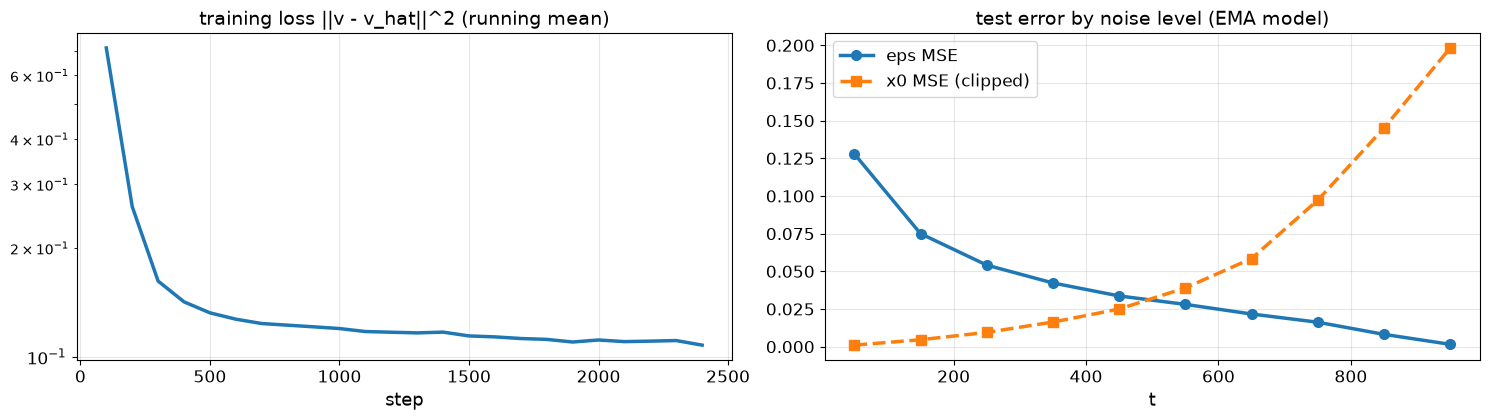

t bucket:      50    150    250    350    450    550    650    750    850    950
eps MSE:    0.128  0.075  0.054  0.042  0.034  0.028  0.022  0.016  0.008  0.002
x0 MSE:     0.001  0.005  0.009  0.016  0.025  0.039  0.059  0.097  0.145  0.198


In [17]:
@torch.no_grad()
def loss_by_t(model, sch, n=500, buckets=10, seed=7):
    g = torch.Generator(device=DEVICE).manual_seed(seed); x0 = to_m1(Xte[:n]).to(DEVICE); y = Yte[:n].to(DEVICE); out = []
    for b in range(buckets):
        t = torch.randint(b * sch.T // buckets, (b + 1) * sch.T // buckets, (n,), device=DEVICE, generator=g)
        eps = torch.randn(x0.shape, generator=g, device=DEVICE); xt = sch.q_sample(x0, t, eps)
        o = model(xt, t, y); e_hat = to_eps(o, xt, t, sch, model.pred); x0_hat = to_x0(o, xt, t, sch, model.pred).clamp(-1, 1)
        out.append(((e_hat - eps).pow(2).mean().item(), (x0_hat - x0).pow(2).mean().item()))
    return np.array(out)

LBT = loss_by_t(UNET, sch)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
ax[0].plot(*zip(*H_UNET), lw=2.5); ax[0].set_yscale("log"); ax[0].set_xlabel("step", fontsize=13)
ax[0].set_title("training loss ||v - v_hat||^2 (running mean)", fontsize=14)
mid = np.arange(50, 1000, 100)
ax[1].plot(mid, LBT[:, 0], "o-", lw=2.5, ms=7, label="eps MSE"); ax[1].plot(mid, LBT[:, 1], "s--", lw=2.5, ms=7, label="x0 MSE (clipped)")
ax[1].set_xlabel("t", fontsize=13); ax[1].set_title("test error by noise level (EMA model)", fontsize=14); ax[1].legend(fontsize=12)
for a in ax: a.grid(alpha=0.3); a.tick_params(labelsize=12)
plt.tight_layout(); plt.show()
print("t bucket:  " + " ".join(f"{m:6d}" for m in mid))
print("eps MSE:   " + " ".join(f"{v:6.3f}" for v in LBT[:, 0]))
print("x0 MSE:    " + " ".join(f"{v:6.3f}" for v in LBT[:, 1]))

### 18.2. Что сеть «видит» на каждом уровне шума

Из одного предсказания сети сразу получается оценка чистого изображения $\hat x_0 = \sqrt{\bar\alpha_t}\,x_t - \sqrt{1-\bar\alpha_t}\,\hat v$ — это оценка условного среднего $\mathbb{E}[x_0 \mid x_t]$. Покажем пары «$x_t$ — $\hat x_0$» для одной тестовой цифры при разных $t$, с правильным классом в качестве условия.

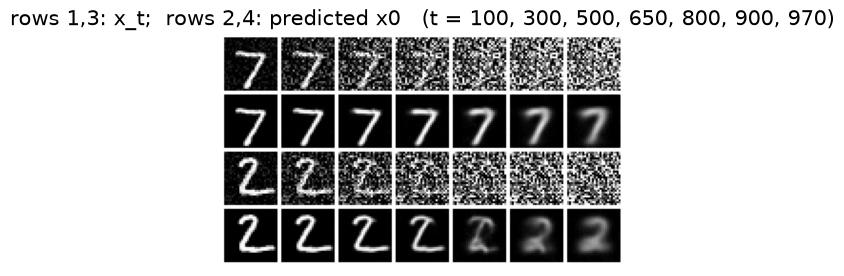

In [18]:
ts = [100, 300, 500, 650, 800, 900, 970]
x0 = to_m1(Xte[:2]).to(DEVICE); y = Yte[:2].to(DEVICE); g = torch.Generator(device=DEVICE).manual_seed(11)
rows_xt, rows_x0 = [], []
with torch.no_grad():
    for k in range(2):
        eps = torch.randn(x0[k:k + 1].shape, generator=g, device=DEVICE)
        for tv in ts:
            t = torch.tensor([tv], device=DEVICE); xt = sch.q_sample(x0[k:k + 1], t, eps)
            rows_xt.append(xt[0]); rows_x0.append(to_x0(UNET(xt, t, y[k:k + 1]), xt, t, sch, UNET.pred).clamp(-1, 1)[0])
grid = torch.stack(rows_xt[:7] + rows_x0[:7] + rows_xt[7:] + rows_x0[7:])
show(to_01(grid), nrow=7, title="rows 1,3: x_t;  rows 2,4: predicted x0   (t = " + ", ".join(map(str, ts)) + ")")

Что видно. 2400 шагов обучения заняли 12,4 минуты (0,31 с на шаг), потеря по $v$ упала с 0,714 (первые 100 шагов) до 0,108 (последние 100), основное падение — за первые 500 шагов. По уровням шума ошибки ведут себя противоположно: ошибка шума снижается с 0,128 при $t \approx 50$ до 0,002 при $t \approx 950$ (при сильном шуме $x_t \approx \epsilon$, и шум угадать легко), а ошибка $\hat x_0$ растёт с 0,001 до 0,198 (при сильном шуме чистое изображение почти не определено).

На сетке до $t = 500$–650 оценка $\hat x_0$ почти совпадает с исходной цифрой. При $t = 800$–970 получается размытая «средняя» семёрка или двойка: это оценка условного среднего $\mathbb{E}[x_0 \mid x_t, y]$, которое при малом сигнале близко к среднему по классу. Сэмплер превращает эту размытую оценку в конкретную цифру за счёт многих маленьких шагов.

## 19. Сэмплеры: DDPM и DDIM, число шагов

### 19.1. Функция генерации

`generate` строит функцию $\epsilon(x_t, t)$ для сэмплера: условную, безусловную (класс `NULL`) или с classifier-free guidance $\tilde\epsilon = (1 + w)\,\epsilon(x_t, y) - w\,\epsilon(x_t, \varnothing)$ ([Ho & Salimans, 2022](https://arxiv.org/abs/2207.12598)). При $w > 0$ условный и безусловный проходы объединяются в один батч двойного размера. Оценка $\hat x_0$ на каждом шаге обрезается до $[-1, 1]$, как в DDPM. В таблицу `RES` складываются результаты всех сэмплеров практикума: число вычислений сети на изображение (NFE), время на 200 изображений и метрики.

In [19]:
RES = {}

def cfg_eps_fn(model, y, w):
    def fn(x, t):
        E = lambda xx, tt, yy: to_eps(model(xx, tt, yy), xx, tt, model.sch, model.pred)   # выход сети -> eps
        if w is None: return E(x, t, torch.full_like(y, NULL))           # безусловная генерация
        if w == 0: return E(x, t, y)
        e_c, e_u = E(torch.cat([x, x]), torch.cat([t, t]), torch.cat([y, torch.full_like(y, NULL)])).chunk(2)
        return (1 + w) * e_c - w * e_u
    return fn

def generate(model, y, w=0.0, steps=50, eta=0.0, seed=0, t_start=None, bs=200, eps_fn=None):
    out = []
    for i in range(0, len(y), bs):
        yb = y[i:i + bs].to(DEVICE)
        fn = eps_fn(yb) if eps_fn is not None else cfg_eps_fn(model, yb, w)
        out.append(sample(fn, (len(yb), 1, 28, 28), model.sch, steps=steps, eta=eta, clip=1.0, seed=seed + i, t_start=t_start).cpu())
    return to_01(torch.cat(out))

def run(name, model, w=0.0, steps=50, eta=0.0, seed=0, t_start=None, eps_fn=None, nfe_per_step=None, store=True):
    with Timer() as tm: x = generate(model, Y_EVAL, w, steps, eta, seed, t_start, eps_fn=eps_fn)
    r = evaluate(x, Y_EVAL)
    n_steps = len(np.unique(np.linspace(model.sch.T - 1 if t_start is None else t_start, 0, steps).round()))
    nfe = n_steps * (nfe_per_step or (2 if (w is not None and w > 0) else 1))
    if store: RES[name] = dict(nfe=nfe, time=tm.s, **r)
    print(f"{name:34s} NFE={nfe:5d}  time={tm.s:6.1f} s  {fmt(r)}", flush=True)
    return x, r

### 19.2. Качество против числа шагов

Сравниваем анцестральный сэмплер DDPM ($\eta = 1$) и детерминированный DDIM ($\eta = 0$) на одной и той же сети, без guidance ($w = 0$, чисто условная модель). Для DDPM с числом шагов меньше $T$ используется та же формула с прореженной сеткой шагов: при $\eta = 1$ это анцестральный сэмплер на «перешаганном» расписании, как в Improved DDPM ([Nichol & Dhariwal, 2021](https://proceedings.mlr.press/v139/nichol21a/nichol21a.pdf)).

In [20]:
SAMPLER_X = {}
for name, kw in [("DDPM eta=1, 1000 steps", dict(steps=1000, eta=1.0)), ("DDPM eta=1, 100 steps", dict(steps=100, eta=1.0)),
                 ("DDPM eta=1, 25 steps", dict(steps=25, eta=1.0)), ("DDIM eta=0, 100 steps", dict(steps=100, eta=0.0)),
                 ("DDIM eta=0, 50 steps", dict(steps=50, eta=0.0)), ("DDIM eta=0, 25 steps", dict(steps=25, eta=0.0)),
                 ("DDIM eta=0, 10 steps", dict(steps=10, eta=0.0)), ("DDIM eta=0, 5 steps", dict(steps=5, eta=0.0))]:
    SAMPLER_X[name], _ = run("U-Net, " + name, UNET, w=0.0, **kw)

U-Net, DDPM eta=1, 1000 steps      NFE= 1000  time= 302.7 s  FD=1.85  conf=0.923  div=0.943  acc=0.960


/tmp/ipykernel_6207/378444187.py:28: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


U-Net, DDPM eta=1, 100 steps       NFE=  100  time=  30.1 s  FD=2.03  conf=0.931  div=0.914  acc=0.955


U-Net, DDPM eta=1, 25 steps        NFE=   25  time=   7.7 s  FD=2.84  conf=0.939  div=0.870  acc=0.940


U-Net, DDIM eta=0, 100 steps       NFE=  100  time=  30.4 s  FD=2.87  conf=0.892  div=0.954  acc=0.905


U-Net, DDIM eta=0, 50 steps        NFE=   50  time=  14.9 s  FD=2.84  conf=0.894  div=0.950  acc=0.910


U-Net, DDIM eta=0, 25 steps        NFE=   25  time=   7.5 s  FD=2.83  conf=0.898  div=0.937  acc=0.920


U-Net, DDIM eta=0, 10 steps        NFE=   10  time=   3.0 s  FD=3.63  conf=0.908  div=0.893  acc=0.935


U-Net, DDIM eta=0, 5 steps         NFE=    5  time=   1.5 s  FD=8.83  conf=0.917  div=0.812  acc=0.935


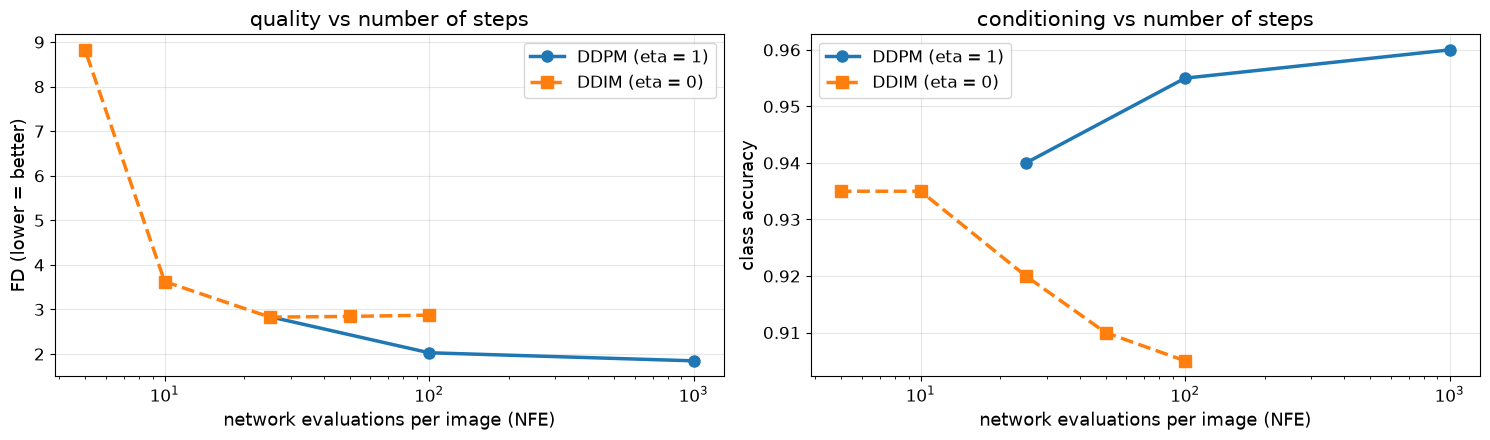

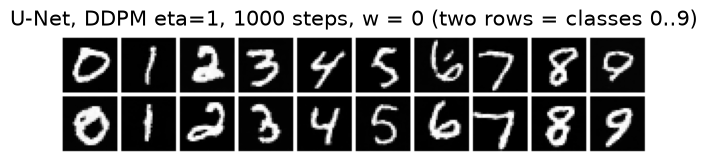

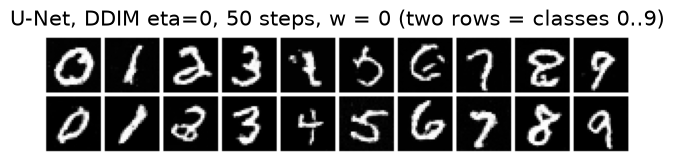

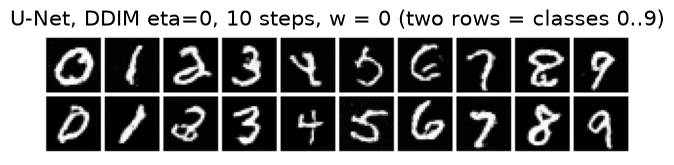

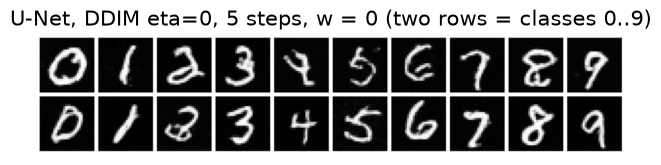

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for eta, mk, lab in [(1.0, "o-", "DDPM (eta = 1)"), (0.0, "s--", "DDIM (eta = 0)")]:
    ks = [k for k in RES if k.startswith("U-Net, DD") and f"eta={eta:g}," in k]
    ax[0].plot([RES[k]["nfe"] for k in ks], [RES[k]["FD"] for k in ks], mk, lw=2.5, ms=8, label=lab)
    ax[1].plot([RES[k]["nfe"] for k in ks], [RES[k]["acc"] for k in ks], mk, lw=2.5, ms=8, label=lab)
ax[0].set_ylabel("FD (lower = better)", fontsize=13); ax[1].set_ylabel("class accuracy", fontsize=13)
for a in ax:
    a.set_xscale("log"); a.set_xlabel("network evaluations per image (NFE)", fontsize=13)
    a.legend(fontsize=12); a.grid(alpha=0.3); a.tick_params(labelsize=12)
ax[0].set_title("quality vs number of steps", fontsize=15); ax[1].set_title("conditioning vs number of steps", fontsize=15)
plt.tight_layout(); plt.show()
for k in ["DDPM eta=1, 1000 steps", "DDIM eta=0, 50 steps", "DDIM eta=0, 10 steps", "DDIM eta=0, 5 steps"]:
    show(SAMPLER_X[k][:20], nrow=10, title=f"U-Net, {k}, w = 0 (two rows = classes 0..9)")

Что видно. DDPM на 1000 шагах даёт FD 1,85, точность класса 0,96 и разнообразие 0,94 за 303 с на 200 изображений. Сокращение DDPM до 100 шагов почти не меняет качества (FD 2,03, acc 0,955) при ускорении в 10 раз; на 25 шагах FD 2,84, а разнообразие падает до 0,87. DDIM держит FD около 2,83–2,87 на 100, 50 и 25 шагах, на 10 шагах — 3,63, и только на 5 шагах заметно ухудшается (FD 8,83, div 0,81). С учётом «пола» FD около 3 для 200 изображений (раздел 12) все варианты с 25 шагами и больше практически неотличимы от реальной выборки по этой метрике; деградация DDIM начинается ниже 10 шагов. Это согласуется с ускорением в 10–50 раз из статьи DDIM ([Song et al., 2020](https://arxiv.org/abs/2010.02502)).

Различие сэмплеров заметно во второй метрике: у DDIM точность класса ниже (0,905–0,92 против 0,94–0,96 у DDPM), а разнообразие выше, и с уменьшением числа шагов DDIM точность растёт (0,905 → 0,935), а разнообразие падает (0,95 → 0,81) — образцы становятся «прототипнее». На сетках видна детерминированность DDIM: при 50, 10 и 5 шагах из одного шума получается почти та же цифра, меняются толщина и чёткость штриха; меньше шагов — более гладкие и простые формы.

## 20. Classifier-free guidance: компромисс fidelity–diversity

Перебираем силу guidance $w$ при DDIM на 50 шагах. Строка `uncond` — та же сеть с пустым классом: это безусловная модель, которую CFG использует как «отрицательный» ориентир. $w = 0$ — чистая условная модель без усиления. В библиотеке diffusers параметр `guidance_scale` равен $1 + w$, так что `guidance_scale = 7.5` соответствует $w = 6{,}5$.

Ожидание по теории (раздел 10): с ростом $w$ растут точность класса и уверенность классификатора, падает разнообразие, а FD сначала улучшается, затем ухудшается.

In [22]:
CFG_X = {}
CFG_X["uncond"], r_unc = run("U-Net, DDIM 50, uncond", UNET, w=None)
for w in [0.0, 0.5, 1.0, 2.0, 4.0, 8.0]:
    CFG_X[w], _ = run(f"U-Net, DDIM 50, CFG w={w:g}", UNET, w=w)

U-Net, DDIM 50, uncond             NFE=   50  time=  15.0 s  FD=15.08  conf=0.700  div=1.395  acc=0.125


/tmp/ipykernel_6207/378444187.py:28: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


U-Net, DDIM 50, CFG w=0            NFE=   50  time=  15.2 s  FD=2.84  conf=0.894  div=0.950  acc=0.910


U-Net, DDIM 50, CFG w=0.5          NFE=  100  time=  32.6 s  FD=6.14  conf=0.961  div=0.816  acc=0.980


U-Net, DDIM 50, CFG w=1            NFE=  100  time=  32.5 s  FD=12.35  conf=0.982  div=0.751  acc=0.990


U-Net, DDIM 50, CFG w=2            NFE=  100  time=  32.8 s  FD=23.78  conf=0.987  div=0.686  acc=1.000


U-Net, DDIM 50, CFG w=4            NFE=  100  time=  33.2 s  FD=40.00  conf=0.989  div=0.639  acc=1.000


U-Net, DDIM 50, CFG w=8            NFE=  100  time=  32.7 s  FD=54.85  conf=0.991  div=0.610  acc=1.000


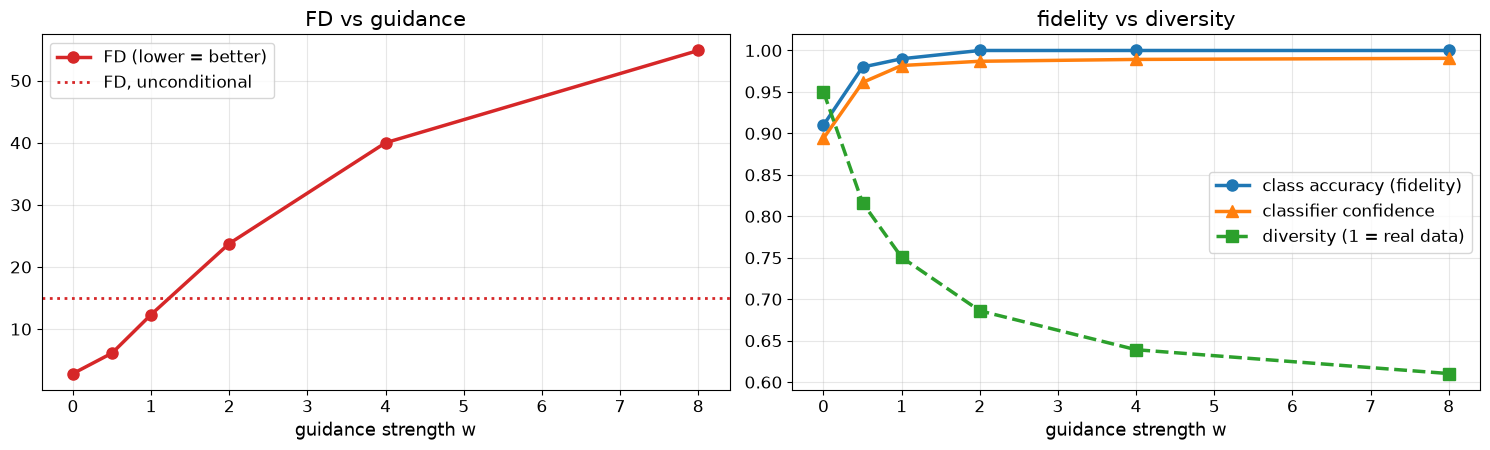

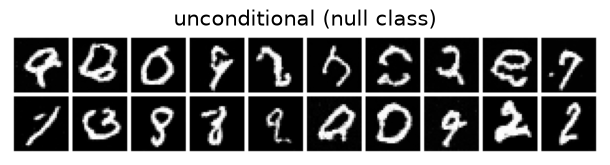

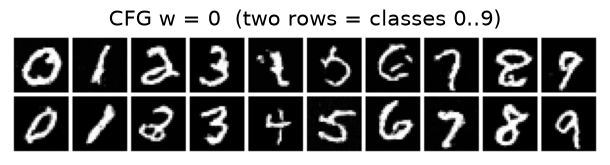

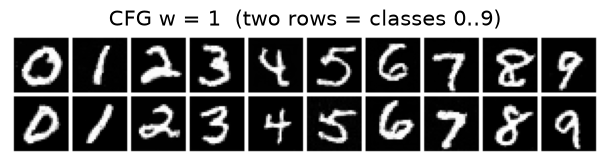

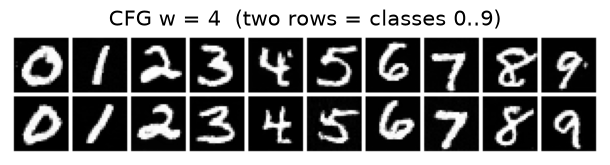

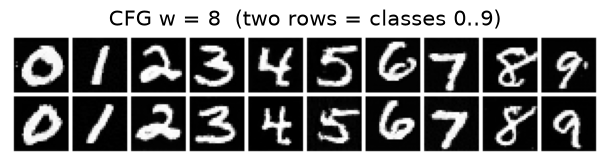

In [23]:
ws = [0.0, 0.5, 1.0, 2.0, 4.0, 8.0]; R = [RES[f"U-Net, DDIM 50, CFG w={w:g}"] for w in ws]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
ax[0].plot(ws, [r["FD"] for r in R], "o-", lw=2.5, ms=8, color="tab:red", label="FD (lower = better)")
ax[0].axhline(RES["U-Net, DDIM 50, uncond"]["FD"], color="tab:red", ls=":", lw=2, label="FD, unconditional")
ax[0].set_xlabel("guidance strength w", fontsize=13); ax[0].set_title("FD vs guidance", fontsize=15); ax[0].legend(fontsize=12)
ax[1].plot(ws, [r["acc"] for r in R], "o-", lw=2.5, ms=8, label="class accuracy (fidelity)")
ax[1].plot(ws, [r["conf"] for r in R], "^-", lw=2.5, ms=8, label="classifier confidence")
ax[1].plot(ws, [r["div"] for r in R], "s--", lw=2.5, ms=8, label="diversity (1 = real data)")
ax[1].set_xlabel("guidance strength w", fontsize=13); ax[1].set_title("fidelity vs diversity", fontsize=15); ax[1].legend(fontsize=12)
for a in ax: a.grid(alpha=0.3); a.tick_params(labelsize=12)
plt.tight_layout(); plt.show()
show(CFG_X["uncond"][:20], title="unconditional (null class)")
for w in [0.0, 1.0, 4.0, 8.0]: show(CFG_X[w][:20], title=f"CFG w = {w:g}  (two rows = classes 0..9)")

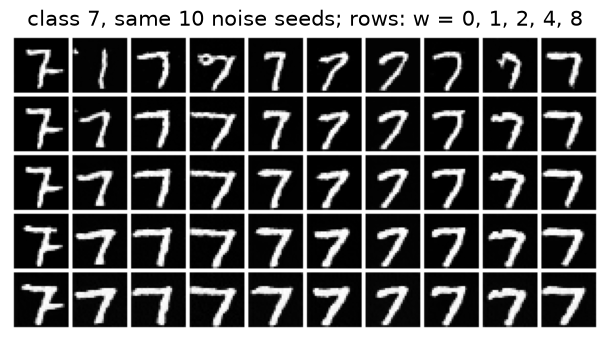

In [24]:
# Одна и та же начальная точка x_T, один класс, разные w: как guidance «доводит» образец до прототипа
y7 = torch.full((10,), 7, dtype=torch.long)
rows = [generate(UNET, y7, w=w, steps=50, seed=123) for w in [0.0, 1.0, 2.0, 4.0, 8.0]]
show(torch.cat(rows), nrow=10, title="class 7, same 10 noise seeds; rows: w = 0, 1, 2, 4, 8")

Что видно. Безусловный режим (пустой класс) даёт FD 15,1 и точность 0,125, то есть около случайных 0,1: сеть рисует цифры, но не те, что запрошены. (Разнообразие 1,395 здесь завышено: разброс считается внутри запрошенного класса, а безусловная модель смешивает классы.) Условная модель при $w = 0$: FD 2,84, точность 0,91, разнообразие 0,95.

С ростом $w$ точность растёт до 0,98 при $w = 0{,}5$, 0,99 при $w = 1$ и 1,0 при $w \ge 2$, уверенность классификатора — с 0,894 до 0,991. Разнообразие монотонно падает: 0,82, 0,75, 0,69, 0,64 и 0,61 для $w$ = 0,5, 1, 2, 4, 8. FD при этом растёт монотонно: 6,1, 12,4, 23,8, 40,0, 54,9. Ожидаемого U-образного минимума FD при $w > 0$ здесь нет: условная модель на MNIST уже при $w = 0$ находится на «полу» метрики, и любое усиление только сужает распределение. В экспериментах на ImageNet, где условная модель далека от идеала, оптимум FID был при малом $w = 0{,}1$–0,3, а при больших $w$ FID тоже рос ([Ho & Salimans, 2022](https://arxiv.org/abs/2207.12598)). Цена CFG — удвоенное NFE: 32,6 с вместо 15,0 с.

На сетках и в строках «одна и та же семёрка»: при $w = 0$ в строке есть семёрка, похожая на единицу, и завитая семёрка; уже при $w = 2$ почти все семёрки одинаковой ширины, с горизонтальной верхней чертой и толстым штрихом, а при $w = 8$ они практически неотличимы. Это и есть компромисс fidelity–diversity.

## 21. Classifier guidance

### 21.1. Классификатор на зашумлённых изображениях

Classifier guidance ([Dhariwal & Nichol, 2021](https://arxiv.org/pdf/2105.05233)) требует отдельного классификатора $p_\phi(y \mid x_t, t)$, обученного на зашумлённых изображениях всех уровней шума: градиент нужен в каждой точке траектории, а обычный классификатор на $x_t$ при большом $t$ бесполезен. Время подаётся тем же синусоидальным эмбеддингом через масштаб и сдвиг признаков.

In [25]:
class NoisyClf(nn.Module):
    def __init__(self, c=32, edim=64):
        super().__init__(); self.edim = edim
        self.t_mlp = nn.Sequential(nn.Linear(edim, edim), nn.SiLU(), nn.Linear(edim, 2 * c + 4 * c))
        self.c1, self.c2, self.c3 = nn.Conv2d(1, c, 3, padding=1), nn.Conv2d(c, 2 * c, 3, stride=2, padding=1), nn.Conv2d(2 * c, 4 * c, 3, stride=2, padding=1)
        self.head = nn.Linear(4 * c, 10); self.c = c
    def forward(self, x, t):
        e = self.t_mlp(timestep_embedding(t, self.edim)); g1, g2 = e[:, :2 * self.c], e[:, 2 * self.c:]
        h = F.silu(self.c1(x)); h = F.silu(self.c2(h) * (1 + g1[:, :, None, None]))
        h = F.silu(self.c3(h) * (1 + g2[:, :, None, None]))
        return self.head(h.mean((2, 3)))

seed_all(0); nclf = NoisyClf().to(DEVICE); opt = torch.optim.Adam(nclf.parameters(), 2e-3)
with Timer() as tm:
    for x, y in batches(Xtr, Ytr, S["bs"], S["steps_ncls"], seed=31):
        x0 = to_m1(x); t = torch.randint(0, T, (len(x0),), device=DEVICE)
        loss = F.cross_entropy(nclf(sch.q_sample(x0, t, torch.randn_like(x0)), t), y)
        opt.zero_grad(); loss.backward(); opt.step()
nclf.eval().requires_grad_(False)
with torch.no_grad():
    g = torch.Generator(device=DEVICE).manual_seed(3); x0 = to_m1(Xte[:1000]).to(DEVICE); yt = Yte[:1000].to(DEVICE)
    accs = []
    for tv in [0, 200, 400, 600, 700, 800, 900, 999]:
        t = torch.full((1000,), tv, device=DEVICE)
        accs.append((nclf(sch.q_sample(x0, t, torch.randn(x0.shape, generator=g, device=DEVICE)), t).argmax(1) == yt).float().mean().item())
print(f"noisy classifier: {tm.s:.0f} s; test accuracy at t = 0, 200, 400, 600, 700, 800, 900, 999: " + ", ".join(f"{a:.2f}" for a in accs))

noisy classifier: 65 s; test accuracy at t = 0, 200, 400, 600, 700, 800, 900, 999: 0.92, 0.91, 0.87, 0.67, 0.47, 0.28, 0.13, 0.09


### 21.2. Guidance градиентом классификатора

Для детерминированного сэмплера guidance записывается как поправка к предсказанию шума: $\hat\epsilon = \epsilon_\theta(x_t) - s\sqrt{1-\bar\alpha_t}\,\nabla_{x_t}\log p_\phi(y \mid x_t)$ ([Dhariwal & Nichol, 2021](https://arxiv.org/pdf/2105.05233)). Это эквивалентно сэмплированию из распределения, пропорционального $p(x)\,p(y \mid x)^s$. Применяем guidance к безусловному режиму той же U-Net (класс `NULL`): вся информация о классе приходит только из градиента классификатора. Метрики по-прежнему считает независимый классификатор-оценщик из раздела 12, а не тот, по градиенту которого идёт guidance.

U-Net, DDIM 50, classifier guid. s=0 NFE=   50  time=  15.1 s  FD=15.08  conf=0.700  div=1.395  acc=0.125


/tmp/ipykernel_6207/378444187.py:28: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


U-Net, DDIM 50, classifier guid. s=1 NFE=   50  time=  18.8 s  FD=18.67  conf=0.732  div=1.291  acc=0.220


U-Net, DDIM 50, classifier guid. s=3 NFE=   50  time=  18.7 s  FD=17.95  conf=0.718  div=1.210  acc=0.325


U-Net, DDIM 50, classifier guid. s=10 NFE=   50  time=  18.5 s  FD=25.04  conf=0.726  div=1.220  acc=0.420


U-Net, DDIM 50, classifier guid. s=30 NFE=   50  time=  19.0 s  FD=60.94  conf=0.731  div=1.221  acc=0.385


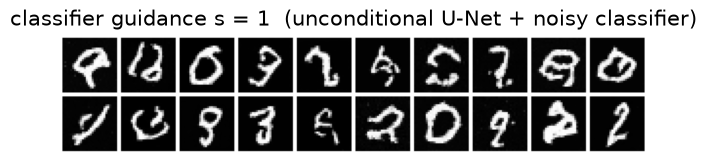

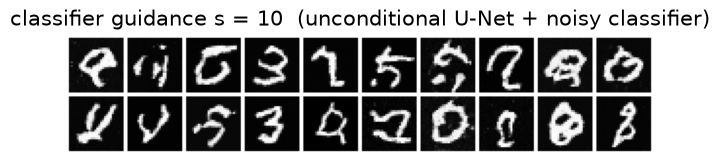

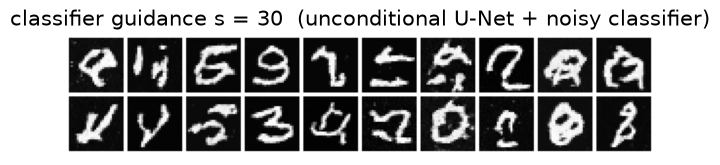

In [26]:
def cg_eps_fn(model, scale):
    def make(yb):
        def fn(x, t):
            with torch.no_grad(): e = to_eps(model(x, t, torch.full_like(yb, NULL)), x, t, model.sch, model.pred)
            if scale == 0: return e
            x_ = x.detach().requires_grad_(True)
            logp = F.log_softmax(nclf(x_, t), -1).gather(1, yb[:, None]).sum()
            grad = torch.autograd.grad(logp, x_)[0]
            return e - scale * (1 - sch.coef("ab", t, x.dim())).sqrt() * grad
        fn.needs_grad = scale != 0
        return fn
    return make

CG_X = {}
for s_cg in [0.0, 1.0, 3.0, 10.0, 30.0]:
    CG_X[s_cg], _ = run(f"U-Net, DDIM 50, classifier guid. s={s_cg:g}", UNET, eps_fn=cg_eps_fn(UNET, s_cg), nfe_per_step=1)
for s_cg in [1.0, 10.0, 30.0]: show(CG_X[s_cg][:20], title=f"classifier guidance s = {s_cg:g}  (unconditional U-Net + noisy classifier)")

Что видно. Классификатор на зашумлённых данных хорошо работает при малом шуме (точность 0,92 при $t = 0$, 0,87 при $t = 400$), но быстро теряет информацию: 0,67 при $t = 600$, 0,28 при $t = 800$, 0,09 при $t = 999$ (случайный уровень). Значит, на первой трети траектории сэмплера градиент классификатора почти бесполезен.

Classifier guidance действительно увеличивает долю запрошенного класса: 0,125 при $s = 0$, 0,22, 0,325 и 0,42 при $s$ = 1, 3, 10, после чего при $s = 30$ точность уже не растёт (0,385). Разнообразие падает с 1,40 до 1,21–1,29. Цена высока: FD ухудшается с 15,1 до 18,7, 18,0, 25,0 и 60,9, уверенность классификатора остаётся около 0,72–0,73, а на сетках при $s = 10$ и 30 видны искажённые штрихи и артефакты — градиент «подгоняет» изображение под классификатор, не делая его более похожим на цифру. По сравнению с CFG эффект слабый: CFG при $w = 0{,}5$ даёт точность 0,98 при FD 6,1. Причины в этом эксперименте — маленький классификатор, обученный 1000 шагов, и неинформативный градиент при большом шуме; в ADM классификатор был большим и обучался долго ([Dhariwal & Nichol, 2021](https://arxiv.org/abs/2105.05233)). Отказ от отдельного классификатора — главное практическое преимущество CFG.

## 22. DiT-mini и расписания шума

### 22.1. Архитектура

DiT ([Peebles & Xie, 2023](https://arxiv.org/abs/2212.09748)) заменяет U-Net обычным трансформером над патчами. Изображение 28×28 режется на патчи $p \times p$ ($p = 4$ на CPU, то есть $(28/4)^2 = 49$ токенов; $p = 2$ на GPU — 196 токенов). Патчи линейно проецируются в размерность $d$, к ним добавляется фиксированное двумерное синусоидальное позиционное кодирование. Время и класс складываются в вектор условия $c$, который управляет каждым блоком через adaLN-Zero: $c$ предсказывает сдвиг, масштаб и «затвор» (gate) для внимания и MLP. Последние линейные слои модуляции инициализированы нулями, поэтому в начале обучения каждый блок — тождественное отображение ([Peebles & Xie, 2023](https://arxiv.org/pdf/2212.09748)). Выходной слой превращает токены обратно в патчи и тоже начинается с нулей.

In [27]:
def sincos_2d(n, d):
    """Фиксированное 2D синусоидальное позиционное кодирование для сетки n x n."""
    y, x = torch.meshgrid(torch.arange(n), torch.arange(n), indexing="ij")
    ex, ey = timestep_embedding(x.flatten(), d // 2, 100), timestep_embedding(y.flatten(), d // 2, 100)
    return torch.cat([ex, ey], -1)

def modulate(x, shift, scale): return x * (1 + scale[:, None]) + shift[:, None]

class DiTBlock(nn.Module):
    def __init__(self, d, heads=4):
        super().__init__(); self.h = heads
        self.n1, self.n2 = nn.LayerNorm(d, elementwise_affine=False, eps=1e-6), nn.LayerNorm(d, elementwise_affine=False, eps=1e-6)
        self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(approximate="tanh"), nn.Linear(4 * d, d))
        self.ada = nn.Sequential(nn.SiLU(), nn.Linear(d, 6 * d))
        nn.init.zeros_(self.ada[-1].weight); nn.init.zeros_(self.ada[-1].bias)    # adaLN-Zero
    def forward(self, x, c):
        sh1, sc1, g1, sh2, sc2, g2 = self.ada(c).chunk(6, -1)
        B, N, D = x.shape
        q, k, v = self.qkv(modulate(self.n1(x), sh1, sc1)).view(B, N, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        a = F.scaled_dot_product_attention(q, k, v).transpose(1, 2).reshape(B, N, D)
        x = x + g1[:, None] * self.proj(a)
        return x + g2[:, None] * self.mlp(modulate(self.n2(x), sh2, sc2))

class DiT(nn.Module):
    def __init__(self, d=128, depth=6, patch=4, heads=4, n_cls=11, img=28):
        super().__init__(); self.p, self.n, self.d = patch, img // patch, d
        self.embed = nn.Conv2d(1, d, patch, stride=patch)
        self.register_buffer("pos", sincos_2d(self.n, d)[None])
        self.t_mlp = nn.Sequential(nn.Linear(d, d), nn.SiLU(), nn.Linear(d, d)); self.cls = nn.Embedding(n_cls, d)
        self.blocks = nn.ModuleList([DiTBlock(d, heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(d, elementwise_affine=False, eps=1e-6)
        self.ada = nn.Sequential(nn.SiLU(), nn.Linear(d, 2 * d)); self.out = nn.Linear(d, patch * patch)
        for m in (self.ada[-1], self.out): nn.init.zeros_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x, t, y):
        h = self.embed(x).flatten(2).transpose(1, 2) + self.pos
        c = self.t_mlp(timestep_embedding(t, self.d)) + self.cls(y)
        for b in self.blocks: h = b(h, c)
        sh, sc = self.ada(c).chunk(2, -1)
        h = self.out(modulate(self.norm(h), sh, sc))                     # (B, N, p*p)
        B = x.shape[0]
        return h.view(B, self.n, self.n, self.p, self.p).permute(0, 1, 3, 2, 4).reshape(B, 1, self.n * self.p, self.n * self.p)

DIT_KW = dict(d=S["dit_d"], depth=S["dit_depth"], patch=S["dit_patch"])
seed_all(0); dit = DiT(**DIT_KW).to(DEVICE)
with torch.no_grad():
    h = dit.embed(xb[:8]).flatten(2).transpose(1, 2) + dit.pos
    c = dit.t_mlp(timestep_embedding(tb[:8], dit.d)) + dit.cls(yb[:8])
    print(f"DiT: {n_params(dit) / 1e6:.2f}M params, {dit.n ** 2} tokens of dim {dit.d}, depth {len(dit.blocks)}")
    print(f"adaLN-Zero at init: max |block(h) - h| = {(dit.blocks[0](h, c) - h).abs().max().item():.1e}, "
          f"max |output| = {dit(xb[:8], tb[:8], yb[:8]).abs().max().item():.1e}")

DiT: 1.26M params, 49 tokens of dim 128, depth 4
adaLN-Zero at init: max |block(h) - h| = 0.0e+00, max |output| = 0.0e+00


### 22.2. Обучение: DiT с косинусным и линейным расписаниями

Обучаем две одинаковые DiT-mini с одинаковым числом шагов, отличается только расписание шума. Затем сравниваем их между собой и с U-Net при одинаковом сэмплере (DDIM, 50 шагов, CFG $w = 1$).

DiT, cosine: 2400 steps in 5.5 min (0.137 s/step), loss last 100 steps 0.1245


DiT, linear: 2400 steps in 5.5 min (0.137 s/step), loss last 100 steps 0.1661


U-Net (cosine), DDIM 50, CFG w=1   NFE=  100  time=  31.9 s  FD=12.35  conf=0.982  div=0.751  acc=0.990


/tmp/ipykernel_6207/378444187.py:28: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


DiT (cosine), DDIM 50, CFG w=1     NFE=  100  time=  14.4 s  FD=14.93  conf=0.965  div=0.769  acc=0.995


DiT (linear), DDIM 50, CFG w=1     NFE=  100  time=  14.6 s  FD=29.32  conf=0.954  div=0.743  acc=0.985


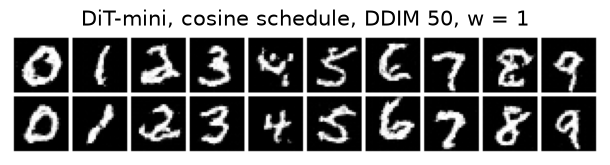

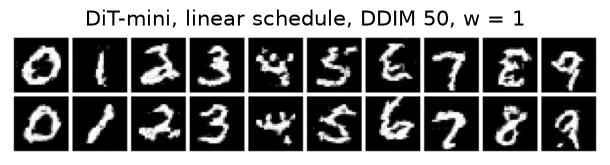

In [28]:
DITS = {}
for sname in ["cosine", "linear"]:
    seed_all(0); m = DiT(**DIT_KW).to(DEVICE)
    with Timer() as tm: DITS[sname], h = train_diffusion(m, SCH[sname], S["steps_dit"])
    print(f"DiT, {sname:6s}: {S['steps_dit']} steps in {tm.s / 60:.1f} min ({tm.s / S['steps_dit']:.3f} s/step), loss last 100 steps {h[-1][1]:.4f}")
DIT_X = {}
_ = run("U-Net (cosine), DDIM 50, CFG w=1", UNET, w=1.0, store=False)
for sname, m in DITS.items():
    DIT_X[sname], _ = run(f"DiT ({sname}), DDIM 50, CFG w=1", m, w=1.0)
for sname in DITS: show(DIT_X[sname][:20], title=f"DiT-mini, {sname} schedule, DDIM 50, w = 1")

### 22.3. Пропуск начала обратного процесса

Проверка из Improved DDPM ([Nichol & Dhariwal, 2021](https://proceedings.mlr.press/v139/nichol21a/nichol21a.pdf)): начнём обратный процесс не с $t = T$, а с $t = 0{,}9T$ или $0{,}8T$, подставив туда чистый шум $\mathcal{N}(0, I)$. Если на последних шагах прямого процесса сигнала почти не осталось, модель этого «не заметит». Если сигнал там ещё есть, старт из чистого шума будет ошибкой, и качество упадёт.

In [29]:
for sname, m in DITS.items():
    s_ = SCH[sname]
    for frac in [1.0, 0.9, 0.8, 0.7]:
        t0 = int(round(frac * (T - 1)))
        _, r = run(f"DiT ({sname}), start at t={t0}", m, w=1.0, steps=50, t_start=t0, store=False)
        print(f"{'':34s} alpha_bar at start = {s_.ab[t0].item():.4f}")

DiT (cosine), start at t=999       NFE=  100  time=  14.4 s  FD=14.93  conf=0.965  div=0.769  acc=0.995


/tmp/ipykernel_6207/378444187.py:28: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


                                   alpha_bar at start = 0.0000


DiT (cosine), start at t=899       NFE=  100  time=  14.3 s  FD=35.57  conf=0.944  div=0.905  acc=0.975


                                   alpha_bar at start = 0.0241


...

                                   alpha_bar at start = 0.0003


DiT (linear), start at t=799       NFE=  100  time=  14.5 s  FD=33.65  conf=0.948  div=0.766  acc=0.980


                                   alpha_bar at start = 0.0015


DiT (linear), start at t=699       NFE=  100  time=  14.3 s  FD=40.81  conf=0.939  div=0.794  acc=0.980


                                   alpha_bar at start = 0.0070


Что видно. DiT-mini имеет 1,26 млн параметров (49 токенов размерности 128, 4 блока); при инициализации и блок, и вся сеть дают ровно тождественное отображение и нулевой выход, как и задумано в adaLN-Zero ([Peebles & Xie, 2023](https://arxiv.org/abs/2212.09748)). Шаг обучения DiT на CPU занимает 0,137 с против 0,31 с у U-Net: 49 токенов дешевле свёрток на полном разрешении 28×28, и генерация 200 изображений с CFG идёт 14,4 с против 32 с.

При одинаковом сэмплере (DDIM 50, $w = 1$) DiT с косинусным расписанием даёт FD 14,9 и точность 0,995 против FD 12,4 и 0,99 у U-Net: качество близкое, хотя у DiT при патче 4 на сетке видны «блочные» штрихи на границах патчей (например, у четвёрки и восьмёрки). Та же DiT с линейным расписанием заметно хуже: FD 29,3 при точности 0,985. Потери на обучении (0,125 и 0,166) между расписаниями не сравнимы: при разных $\bar\alpha_t$ цель $v$ распределена по-разному.

Пропуск начала процесса. Для косинусного расписания старт из чистого шума при $t = 899$, 799 и 699 (где $\bar\alpha_t$ = 0,024, 0,094 и 0,203) ухудшает FD с 14,9 до 35,6, 90,9 и 205,4, точность падает до 0,65: весь диапазон шагов используется, и сигнал на старте пропускать нельзя. Для линейного расписания те же старты ($\bar\alpha_t$ = 0,0003, 0,0015 и 0,007) почти безвредны: FD 29,3 → 30,7 → 33,7 → 40,8, точность 0,98. Последние 20–30% линейного расписания почти не содержат сигнала, что воспроизводит наблюдение Improved DDPM о пропуске до 20% обратного процесса ([Nichol & Dhariwal, 2021](https://proceedings.mlr.press/v139/nichol21a/nichol21a.pdf)).

## 23. Сводка

Все сэмплеры и модели практикума в одной таблице: NFE — число вычислений диффузионной сети на одно изображение (CFG удваивает его), время — на 200 изображений на этом устройстве. Строка `real test sample` — ориентир: столько дают 200 настоящих тестовых изображений.

In [30]:
print(f"{'model / sampler':44s} {'NFE':>5s} {'time,s':>7s} {'FD':>7s} {'acc':>6s} {'conf':>6s} {'div':>6s}")
print(f"{'real test sample':44s} {'-':>5s} {'-':>7s} {base_real['FD']:7.2f} {base_real['acc']:6.3f} {base_real['conf']:6.3f} {base_real['div']:6.3f}")
for k, r in RES.items():
    print(f"{k:44s} {r['nfe']:5d} {r['time']:7.1f} {r['FD']:7.2f} {r['acc']:6.3f} {r['conf']:6.3f} {r['div']:6.3f}")
print(f"\nn_eval={S['n_eval']} samples per row; FAST_DEV_RUN={FAST_DEV_RUN}; device={DEVICE}")

model / sampler                                NFE  time,s      FD    acc   conf    div
real test sample                                 -       -    3.04  0.940  0.924  1.000
U-Net, DDPM eta=1, 1000 steps                 1000   302.7    1.85  0.960  0.923  0.943
U-Net, DDPM eta=1, 100 steps                   100    30.1    2.03  0.955  0.931  0.914
U-Net, DDPM eta=1, 25 steps                     25     7.7    2.84  0.940  0.939  0.870
U-Net, DDIM eta=0, 100 steps                   100    30.4    2.87  0.905  0.892  0.954
U-Net, DDIM eta=0, 50 steps                     50    14.9    2.84  0.910  0.894  0.950
U-Net, DDIM eta=0, 25 steps                     25     7.5    2.83  0.920  0.898  0.937
U-Net, DDIM eta=0, 10 steps                     10     3.0    3.63  0.935  0.908  0.893
U-Net, DDIM eta=0, 5 steps                       5     1.5    8.83  0.935  0.917  0.812
U-Net, DDIM 50, uncond                          50    15.0   15.08  0.125  0.700  1.395
U-Net, DDIM 50, CFG w=0         

Что видно. По соотношению «качество — время» в этом прогоне лучшие точки — DDIM на 25 шагах (7,5 с, FD 2,83, точность 0,92) и DDPM на 100 шагах (30 с, FD 2,03, точность 0,955); 1000 шагов DDPM дают лишь небольшой выигрыш (FD 1,85) за 10-кратное время. Все значения FD ниже примерно 3 не отличаются от реальной выборки (3,04) при 200 изображениях. Guidance — отдельная ось: CFG доводит точность класса до 0,98–1,0 ценой разнообразия (0,61–0,82) и FD (6–55), а classifier guidance в нашей постановке даёт точность не выше 0,42. DiT-mini при вдвое меньшем времени сэмплинга близок к U-Net по качеству, косинусное расписание для него вдвое лучше линейного по FD.

Все числа получены на CPU в режиме `FAST_DEV_RUN` (урезанные сети, 2400 шагов обучения, 200 изображений на оценку). На GPU в Colab сети и выборки крупнее, и числа будут другими; эта ветка не проверялась, поэтому переносить стоит направления эффектов, а не значения.

# Выводы

1. Диффузионная модель задаёт фиксированный прямой процесс, который за $T$ шагов превращает данные в гауссов шум, и учит сеть обращать каждый шаг. Замкнутая форма $q(x_t \mid x_0)$ делает обучение дешёвым: один случайный $t$ на пример, одна регрессия.
2. ELBO распадается на KL между гауссианами, и каждое слагаемое — взвешенная MSE предсказания шума. $L_{\text{simple}}$ отбрасывает веса; в практикуме у линейного расписания эти веса в 58,8 раза больше при $t = 2$, чем при $t = T$, а у косинусного почти весь вес приходится на последний шаг.
3. Цели $\epsilon$, $x_0$ и $v$ эквивалентны алгебраически, но не численно. В двумерном примере $\epsilon$-модель давала ошибку $\hat x_0$ до 7227 при $t \ge 900$ и полностью ломала DDIM (96% точек вне мод), $x_0$-модель плохо оценивала шум при малых $t$, а $v$-модель была точной на всех уровнях.
4. Предсказание шума — это оценка score: $\nabla \log p_t = -\epsilon/\sqrt{1-\bar\alpha_t}$. DDPM — denoising score matching на тысяче уровней шума, а сэмплирование — дискретизация обратной SDE. У той же SDE есть детерминированная probability flow ODE, и DDIM — её дискретизация.
5. На MNIST DDIM на 25 шагах дал FD 2,83 против 1,85 у DDPM на 1000 шагах при 40-кратной экономии времени; заметная деградация началась только на 5 шагах (FD 8,83).
6. U-Net подаёт время и класс через AdaGN в каждый остаточный блок, DiT — через adaLN-Zero, при котором каждый блок стартует как тождественное отображение. DiT-mini был близок к U-Net по качеству (FD 14,9 против 12,4 при CFG $w = 1$) при вдвое меньшем времени генерации.
7. Classifier-free guidance — самый практичный способ управлять компромиссом fidelity–diversity: с ростом $w$ от 0 до 8 точность класса выросла с 0,91 до 1,0, а разнообразие упало с 0,95 до 0,61. Classifier guidance с небольшим шумным классификатором дал точность не выше 0,42 и артефакты.
8. Расписание шума определяет, как шаги распределены по SNR. У линейного расписания треть шагов приходится на SNR < 0,01, и пропуск последних 30% обратного процесса почти не ухудшил FD (29,3 → 40,8); у косинусного тот же пропуск увеличил FD с 14,9 до 205.

# Контрольные вопросы

1. Почему множитель $\sqrt{1-\beta_t}$ в прямом процессе называют variance preserving? Чему равна дисперсия $x_t$, если $\mathrm{Var}(x_0) = 0{,}25$ и $\bar\alpha_t = 0{,}2$?
   Ответ: при $\mathrm{Var}(x_{t-1}) = 1$ дисперсия $x_t$ остаётся равной 1. Здесь $\mathrm{Var}(x_t) = 0{,}2 \cdot 0{,}25 + 0{,}8 = 0{,}85$.
2. Чему равно $\bar\alpha_T$ у линейного расписания DDPM и какая амплитуда сигнала остаётся в $x_T$?
   Ответ: $4{,}04 \cdot 10^{-5}$ (вывод раздела 13); амплитуда $\sqrt{\bar\alpha_T} \approx 0{,}0064$, то есть 0,6% исходной.
3. Выведите дисперсию шума в $x_2$ через $\alpha_1, \alpha_2$.
   Ответ: $\alpha_2(1-\alpha_1) + (1-\alpha_2) = 1 - \alpha_1\alpha_2 = 1 - \bar\alpha_2$.
4. Чему равна апостериорная дисперсия $\tilde\beta_1$ и почему?
   Ответ: $\tilde\beta_1 = \frac{1-\bar\alpha_0}{1-\bar\alpha_1}\beta_1 = 0$, так как $\bar\alpha_0 = 1$: при известных $x_1$ и $x_0$ про $x_0$ всё известно.
5. Почему DDPM обучают на $L_{\text{simple}}$, а не на полной ELBO? Приведите числа из статьи.
   Ответ: $L_{\text{simple}}$ снижает вес малых $t$ и даёт лучшие образцы; на CIFAR-10 полная граница дала $\le 3{,}70$ бит и FID 13,51, $L_{\text{simple}}$ — $\le 3{,}75$ бит и FID 3,17 ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)).
6. Пусть $a_t = 0{,}6$, $\sigma_t = 0{,}8$, $x_t = 1{,}0$, сеть предсказала $\hat v = 0{,}5$. Найдите $\hat x_0$ и $\hat\epsilon$ и проверьте результат.
   Ответ: $\hat x_0 = 0{,}6 \cdot 1 - 0{,}8 \cdot 0{,}5 = 0{,}2$; $\hat\epsilon = 0{,}8 \cdot 1 + 0{,}6 \cdot 0{,}5 = 1{,}1$. Проверка: $0{,}6 \cdot 0{,}2 + 0{,}8 \cdot 1{,}1 = 1{,}0$.
7. Во сколько раз ошибка $\hat\epsilon$ усиливается при переводе в $\hat x_0$ на последнем шаге косинусного и линейного расписаний?
   Ответ: в $\sqrt{1-\bar\alpha_T}/\sqrt{\bar\alpha_T}$: около $2{,}0 \cdot 10^4$ для косинусного ($\bar\alpha_T = 2{,}43 \cdot 10^{-9}$) и около 157 для линейного.
8. Как связаны MSE по $\epsilon$, по $v$ и по $x_0$? Найдите веса при $\bar\alpha_t = 0{,}2$.
   Ответ: $\|\Delta\epsilon\|^2 = \mathrm{SNR}\,\|\Delta x_0\|^2$, $\|\Delta v\|^2 = (1+\mathrm{SNR})\,\|\Delta x_0\|^2$. При $\bar\alpha_t = 0{,}2$ SNR = 0,25, веса 0,25 и 1,25.
9. Сеть при $\bar\alpha_t = 0{,}36$ предсказала $\hat\epsilon = 0{,}6$ (в одной координате). Чему равна оценка score?
   Ответ: $-0{,}6/\sqrt{0{,}64} = -0{,}75$.
10. Почему NCSN использует много уровней шума? Что показал одноуровневый Ланжевен в разделе 16?
    Ответ: данные лежат около многообразия низкой размерности, где score вне данных оценивается плохо, а Ланжевен медленно переходит между модами ([Song & Ermon, 2019](https://arxiv.org/abs/1907.05600)). В практикуме при $t = 5$ доля тяжёлых мод получилась 0,727 вместо 0,794, а относительная ошибка выученного score при $t = 30$ — 33% против 2,2% при $t = 800$.
11. Чем probability flow ODE отличается от обратной SDE и что у них общего?
    Ответ: у них одинаковые маргиналы $p_t$, но ODE детерминирована: один $x_T$ всегда даёт один образец, возможно точное правдоподобие и решатели высокого порядка ([Song et al., 2021](https://arxiv.org/abs/2011.13456)). В разделе 16 два запуска DDIM из одного $x_T$ совпали точно, у DDPM конечные точки разошлись в среднем на 2,36.
12. Покажите, что при $\eta = 1$ и $t' = t-1$ шум DDIM совпадает с апостериорной дисперсией DDPM.
    Ответ: $\sigma^2 = \frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\left(1 - \frac{\bar\alpha_t}{\bar\alpha_{t-1}}\right) = \frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\,\beta_t = \tilde\beta_t$, так как $\bar\alpha_t/\bar\alpha_{t-1} = \alpha_t = 1 - \beta_t$.
13. Сколько NFE нужно на 200 изображений при DDIM 50 с CFG и при DDIM 50 с classifier guidance? Почему по времени они различаются меньше, чем по NFE?
    Ответ: CFG — 100 вызовов денойзера на изображение (условный и безусловный); classifier guidance — 50 вызовов денойзера плюс 50 прямых и обратных проходов классификатора. В практикуме: 32,6 с против 18,8 с, потому что классификатор намного меньше U-Net.
14. Как перевести `guidance_scale = 7.5` из diffusers в $w$ Ho и Salimans? Вычислите $\tilde\epsilon$ при $\epsilon_c = 0{,}3$, $\epsilon_u = 0{,}1$, $w = 2$.
    Ответ: $w = 6{,}5$. $\tilde\epsilon = 3 \cdot 0{,}3 - 2 \cdot 0{,}1 = 0{,}7$.
15. Почему при guidance FD обычно имеет U-образную зависимость от $w$, а в практикуме он рос монотонно?
    Ответ: малое усиление улучшает качество образцов, большое уничтожает разнообразие; на ImageNet минимум FID был при $w = 0{,}1$–0,3 ([Ho & Salimans, 2022](https://arxiv.org/abs/2207.12598)). На MNIST условная модель уже при $w = 0$ находится на «полу» FD (2,84 при 3,04 у реальной выборки), и усиление только сужает распределение: FD 6,1 при $w = 0{,}5$ и 54,9 при $w = 8$.
16. Сколько токенов у DiT на MNIST при $p = 4$ и $p = 2$ и у DiT-XL/2 для изображений 256×256?
    Ответ: 49 и 196; у DiT-XL/2 латент 32×32 и патч 2, то есть 256 токенов ([Peebles & Xie, 2023](https://arxiv.org/abs/2212.09748)).
17. Что даёт нулевая инициализация в adaLN-Zero и как это проверено в практикуме?
    Ответ: затворы $\alpha$ равны нулю, поэтому каждый блок — тождественное отображение и обучение начинается со стабильной «пустой» сети. В разделе 22 $\max|\mathrm{block}(h) - h| = 0$ и выход сети ровно 0.
18. Какой самый длинный период у синусоидального кодирования времени размерности 64 и почему он больше $T$?
    Ответ: $2\pi \cdot 10000^{31/32} \approx 4{,}7 \cdot 10^4$ шагов. Низкочастотные компоненты монотонны на всём диапазоне и различают «рано» и «поздно», высокочастотные — соседние шаги.
19. Почему пропуск начала обратного процесса почти безвреден для линейного расписания и вреден для косинусного? Приведите числа.
    Ответ: при $t = 699$ у линейного $\bar\alpha_t = 0{,}007$ (сигнала почти нет), у косинусного — 0,203. Старт из чистого шума при $t = 699$ увеличил FD у линейного с 29,3 до 40,8, у косинусного — с 14,9 до 205,4.
20. Перечислите исправления, предложенные Lin et al. для расписаний с ненулевым конечным SNR, и какое из них использовано в практикуме.
    Ответ: перемасштабирование к нулевому конечному SNR, $v$-предсказание, старт сэмплера с последнего шага, перемасштабирование CFG ([Lin et al., 2024](https://arxiv.org/abs/2305.08891)). В практикуме — $v$-предсказание и старт с $t = T - 1$; у косинусного расписания конечный SNR и так близок к нулю ($2{,}4 \cdot 10^{-9}$).
21. Почему FD реальной выборки из 200 изображений равен 3,04, а не 0, и как это влияет на выводы?
    Ответ: из 200 точек средние и ковариации 128-мерных признаков оцениваются с большой ошибкой, и FD смещён вверх. Различия FD меньше 1–2 между моделями блокнота не значимы; для выводов нужны тысячи образцов, как в протоколе FID ([Heusel et al., 2017](https://arxiv.org/abs/1706.08500)).

# Задания

1. Расписания. Добавьте сигмоидное расписание или сдвиг $\log\mathrm{SNR}$ на константу, как предлагают для высоких разрешений ([Hoogeboom et al., 2023](https://arxiv.org/abs/2301.11093)). Постройте графики раздела 13 и повторите эксперимент с пропуском начала из раздела 22. Какой сдвиг оптимален для 28×28?
2. Параметризация на изображениях. Обучите U-Net с `PRED = "eps"` и сравните таблицу сэмплеров с $v$-моделью. Повторите для линейного расписания, где $\bar\alpha_T = 4 \cdot 10^{-5}$. Подтвердите или опровергните вывод раздела 15 о том, что DDIM с $\epsilon$-моделью ломается из-за первого шага; проверьте, помогает ли старт с $t = 980$.
3. Решатель второго порядка. Реализуйте шаг Хойна (Heun) для probability flow ODE в стиле EDM ([Karras et al., 2022](https://arxiv.org/abs/2206.00364)) и сравните с DDIM при одинаковом NFE (10, 20, 50).
4. Predictor-corrector. Добавьте к DDIM один-два шага Ланжевена на каждом уровне шума ([Song et al., 2021](https://arxiv.org/abs/2011.13456)). Сначала проверьте на двумерной задаче, удаётся ли получить долю тяжёлых мод 0,794 (у отжига в разделе 16 было 0,856), затем на MNIST.
5. Компромисс guidance. Постройте кривую «точность класса — разнообразие» для CFG при $w \in [0, 2]$ с шагом 0,25 и для classifier guidance при $s \in [0, 30]$ на одном графике. Увеличьте выборку до 2000 изображений и проверьте, появляется ли минимум FD при малом $w$.
6. Guidance с интервалом. Включайте CFG только на части траектории (например, при $t \in [200, 700]$). Как меняются точность, разнообразие и FD по сравнению с постоянным $w$?
7. DiT. Сравните DiT-mini с патчами 2 и 4 при одинаковом времени обучения, а также замените adaLN-Zero на in-context-условие (токены времени и класса в последовательности). Повторите сравнение условий из DiT ([Peebles & Xie, 2023](https://arxiv.org/abs/2212.09748)).
8. Латентная диффузия. Возьмите VAE-токенизатор из лекции 11, закодируйте MNIST в латент и обучите DiT-mini в латентном пространстве ([Rombach et al., 2022](https://arxiv.org/pdf/2112.10752)). Сравните время обучения, время генерации и метрики с пиксельной моделью.

# Источники

1. Sohl-Dickstein J. et al. Deep Unsupervised Learning using Nonequilibrium Thermodynamics. ICML 2015. https://arxiv.org/abs/1503.03585
2. Ho J., Jain A., Abbeel P. Denoising Diffusion Probabilistic Models. NeurIPS 2020. https://arxiv.org/abs/2006.11239
3. Nichol A., Dhariwal P. Improved Denoising Diffusion Probabilistic Models. ICML 2021. https://proceedings.mlr.press/v139/nichol21a/nichol21a.pdf
4. Song J., Meng C., Ermon S. Denoising Diffusion Implicit Models. ICLR 2021. https://arxiv.org/abs/2010.02502
5. Hyvärinen A. Estimation of Non-Normalized Statistical Models by Score Matching. JMLR, 2005. https://jmlr.org/papers/v6/hyvarinen05a.html
6. Vincent P. A Connection Between Score Matching and Denoising Autoencoders. Neural Computation, 2011. https://www.iro.umontreal.ca/~vincentp/Publications/smdae_techreport.pdf
7. Song Y., Ermon S. Generative Modeling by Estimating Gradients of the Data Distribution. NeurIPS 2019. https://arxiv.org/abs/1907.05600
8. Song Y. et al. Score-Based Generative Modeling through Stochastic Differential Equations. ICLR 2021. https://arxiv.org/abs/2011.13456
9. Kingma D. et al. Variational Diffusion Models. NeurIPS 2021. https://arxiv.org/abs/2107.00630
10. Salimans T., Ho J. Progressive Distillation for Fast Sampling of Diffusion Models. ICLR 2022. https://arxiv.org/abs/2202.00512
11. Karras T. et al. Elucidating the Design Space of Diffusion-Based Generative Models. NeurIPS 2022. https://arxiv.org/abs/2206.00364
12. Dhariwal P., Nichol A. Diffusion Models Beat GANs on Image Synthesis. NeurIPS 2021. https://arxiv.org/abs/2105.05233
13. Ho J., Salimans T. Classifier-Free Diffusion Guidance. 2022. https://arxiv.org/abs/2207.12598
14. Peebles W., Xie S. Scalable Diffusion Models with Transformers. ICCV 2023. https://arxiv.org/abs/2212.09748
15. Ronneberger O., Fischer P., Brox T. U-Net: Convolutional Networks for Biomedical Image Segmentation. MICCAI 2015. https://arxiv.org/abs/1505.04597
16. Rombach R. et al. High-Resolution Image Synthesis with Latent Diffusion Models. CVPR 2022. https://arxiv.org/pdf/2112.10752
17. Lin S. et al. Common Diffusion Noise Schedules and Sample Steps are Flawed. WACV 2024. https://arxiv.org/abs/2305.08891
18. Hoogeboom E., Heek J., Salimans T. simple diffusion: End-to-end diffusion for high resolution images. ICML 2023. https://arxiv.org/abs/2301.11093
19. Esser P. et al. Scaling Rectified Flow Transformers for High-Resolution Image Synthesis. ICML 2024. https://arxiv.org/abs/2403.03206
20. Heusel M. et al. GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium (FID). NeurIPS 2017. https://arxiv.org/abs/1706.08500
21. Xiao Z., Kreis K., Vahdat A. Tackling the Generative Learning Trilemma with Denoising Diffusion GANs. ICLR 2022. https://arxiv.org/abs/2112.07804
22. LeCun Y., Cortes C., Burges C. The MNIST database of handwritten digits. https://yann.lecun.org/exdb/mnist/index.html